#1.0 Exploratory Data Analysis with Big Data

##1.1 Loading and Inspecting the Data

In [0]:
#loading a single file on spark
combine_tracking_df_single = (spark.read
        .option("header", "true")
        .option("inferSchema", "true")
        .csv("/Volumes/nfl_bigdatabowl/nfl_2027/nfl_2027/combine_tracking.csv"))

In [0]:
combine_tracking_df_single.columns

['draft_year',
 'event_id',
 'nfl_id',
 'entity_type',
 'time',
 'drill_type',
 'drill_name',
 'attempt',
 'x',
 'y',
 's',
 'a',
 'dis',
 'dir']

In [0]:
len(combine_tracking_df_single.columns)

14

In [0]:
combine_tracking_df_single.show(5)

+----------+--------------------+------+-----------+--------------------+---------------+--------------------+-------+-----------+-----------+-----------+-----------+-----------+-----------+
|draft_year|            event_id|nfl_id|entity_type|                time|     drill_type|          drill_name|attempt|          x|          y|          s|          a|        dis|        dir|
+----------+--------------------+------+-----------+--------------------+---------------+--------------------+-------+-----------+-----------+-----------+-----------+-----------+-----------+
|      2025|20250302100900_17...| 58286|     PLAYER|2025-03-02 18:56:...|SKILL_DRILLS_OL|OL_PULL_DRILL_FOL...|      4|44.78592428|28.28552755|0.220828156|0.682442751|0.011085185|250.2785762|
|      2025|20250302100900_17...| 58286|     PLAYER|2025-03-02 18:56:...|SKILL_DRILLS_OL|OL_PULL_DRILL_FOL...|      4|44.72378031|28.29739126|0.332931499|0.619550768|0.003864436|257.3192055|
|      2025|20250302100900_17...| 58286|     

In [0]:
combine_tracking_df_single.select("drill_type").distinct().show(truncate=False)

+----------------+
|drill_type      |
+----------------+
|SKILL_DRILLS_DL |
|FORTY_YARD_DASH |
|SKILL_DRILLS_WR |
|THREE_CONE_DRILL|
|SKILL_DRILLS_TE |
|SHORT_SHUTTLE   |
|SKILL_DRILLS_DB |
|SKILL_DRILLS_OL |
|SKILL_DRILLS_LB |
+----------------+



In [0]:
combine_tracking_df_single.select("drill_name").distinct().show(truncate=False) #truncate=False to remove the truncation

+--------------------------------------------+
|drill_name                                  |
+--------------------------------------------+
|W_DRILL                                     |
|TERYL_AUSTIN_DRILL_2                        |
|SHORT_ZONE_BREAK_FORWARD                    |
|SHORT_ZONE_BREAK_INSIDE                     |
|FORTY_YARD_DASH                             |
|PASS_RUSH_DROP                              |
|OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT          |
|FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE      |
|LINE_DRILL                                  |
|FOUR_BAG_AGILITY_DRILL                      |
|FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION |
|TERYL_AUSTIN_DRILL_1                        |
|SHORT_ZONE_BREAK_FLAT_WHEEL                 |
|SCREEN_DRILL                                |
|THREE_CONE_DRILL                            |
|PASS_RUSH_DRILL                             |
|BODY_CONTROL_DRILL                          |
|BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL      |
|GAUNTLET_DRI

In [0]:
from pyspark.sql.functions import col
combine_tracking_df_single.filter(col("drill_type") == "FORTY_YARD_DASH").select("drill_name").distinct().show(truncate=False)

+---------------+
|drill_name     |
+---------------+
|FORTY_YARD_DASH|
+---------------+



In [0]:
combine_tracking_df_single.select("drill_name").distinct().count()

56

In [0]:
Forty_yard_dash = combine_tracking_df_single.filter(combine_tracking_df_single.drill_name == "FORTY_YARD_DASH") #Transformation

In [0]:
Forty_yard_dash.count() #action

41500

In [0]:
Forty_yard_dash.show(5)

+----------+--------------------+------+-----------+--------------------+---------------+---------------+-------+-----------+------------+-----------+-----------+-----------+-----------+
|draft_year|            event_id|nfl_id|entity_type|                time|     drill_type|     drill_name|attempt|          x|           y|          s|          a|        dis|        dir|
+----------+--------------------+------+-----------+--------------------+---------------+---------------+-------+-----------+------------+-----------+-----------+-----------+-----------+
|      2025|20250302101000_17...| 58896|     PLAYER|2025-03-02 20:08:...|FORTY_YARD_DASH|FORTY_YARD_DASH|      1|9.721076965|-0.354534666|0.628482223|2.533120602|0.002005007| 125.157716|
|      2025|20250302101000_17...| 58896|     PLAYER|2025-03-02 20:08:...|FORTY_YARD_DASH|FORTY_YARD_DASH|      1|9.781612396|-0.394934535|0.874184529|2.969284515|0.004011577| 118.872079|
|      2025|20250302101000_17...| 58896|     PLAYER|2025-03-02 20

In [0]:
combine_tracking_df_single.printSchema()

root
 |-- draft_year: integer (nullable = true)
 |-- event_id: string (nullable = true)
 |-- nfl_id: integer (nullable = true)
 |-- entity_type: string (nullable = true)
 |-- time: timestamp (nullable = true)
 |-- drill_type: string (nullable = true)
 |-- drill_name: string (nullable = true)
 |-- attempt: integer (nullable = true)
 |-- x: double (nullable = true)
 |-- y: double (nullable = true)
 |-- s: double (nullable = true)
 |-- a: double (nullable = true)
 |-- dis: double (nullable = true)
 |-- dir: double (nullable = true)



In [0]:
combine_tracking_df_single.describe().show()

+-------+------------------+--------------------+-----------------+-----------+----------------+--------------------+------------------+------------------+------------------+-----------------+------------------+------------------+------------------+
|summary|        draft_year|            event_id|           nfl_id|entity_type|      drill_type|          drill_name|           attempt|                 x|                 y|                s|                 a|               dis|               dir|
+-------+------------------+--------------------+-----------------+-----------+----------------+--------------------+------------------+------------------+------------------+-----------------+------------------+------------------+------------------+
|  count|            463189|              463189|           463189|     463189|          463189|              463189|            463189|            463189|            463189|           463189|            463189|            463189|            463189|


##1.2 Loading multiple datasets to a dataframe

In [0]:
# ──────────────────────────────────────────────────────────────────────────────
# NFL Big Data Bowl 2027 — Data Ingestion
# Loads 2 Unity Catalog tables and 7 CSV files from a UC volume as Spark
# DataFrames for downstream analysis.
# ──────────────────────────────────────────────────────────────────────────────

VOLUME_PATH = "/Volumes/nfl_bigdatabowl/nfl_2027/nfl_2027"


# ── Helper: load a CSV from the Unity Catalogue volume with header + schema inference ──
def load_volume_csv(filename, volume_path=VOLUME_PATH):
    """Read a CSV file from the Unity Catalogue volume as a Spark DataFrame."""
    return (
        spark.read
        .option("header", "true")
        .option("inferSchema", "true")
        .csv(f"{volume_path}/{filename}")
    )


# ── 1. Unity Catalog Tables (2) ──
# Pre-registered Delta tables — loaded directly via spark.table()
combine_results_df       = spark.table("nfl_bigdatabowl.nfl_2027.combine_results")
game_tracking_2025_df    = spark.table("nfl_bigdatabowl.nfl_2027.game_tracking_2025")

# ── 2. Volume CSV Files (7) ──
# Raw CSVs stored in the nfl_2027 Unity Catalog volume
combine_tracking_df         = load_volume_csv("combine_tracking.csv")
game_tracking_2023_df       = load_volume_csv("game_tracking_2023.csv")
game_tracking_2024_df       = load_volume_csv("game_tracking_2024.csv")
games_df                    = load_volume_csv("games.csv")
player_career_successes_df  = load_volume_csv("player_career_successes.csv")
player_play_df              = load_volume_csv("player_play.csv")
players_df                  = load_volume_csv("players.csv")

print("✅ All 9 DataFrames loaded successfully.")

✅ All 9 DataFrames loaded successfully.


In [0]:
# ── Quick Verification: schema + row counts for all 9 DataFrames ──
# Lightweight check — schema is free; counts trigger a scan.

dataframes = {
    # Unity Catalog tables
    "combine_results_df"      : combine_results_df,
    "game_tracking_2025_df"   : game_tracking_2025_df,
    # Volume CSV files
    "combine_tracking_df"         : combine_tracking_df,
    "game_tracking_2023_df"       : game_tracking_2023_df,
    "game_tracking_2024_df"       : game_tracking_2024_df,
    "games_df"                    : games_df,
    "player_career_successes_df"  : player_career_successes_df,
    "player_play_df"              : player_play_df,
    "players_df"                  : players_df,
}

for name, df in dataframes.items():
    print(f"{name}: {len(df.columns)} cols")
    df.printSchema()

combine_results_df: 18 cols
root
 |-- draft_year: long (nullable = true)
 |-- nfl_id: long (nullable = true)
 |-- combine_position: string (nullable = true)
 |-- combine_height: double (nullable = true)
 |-- combine_weight: long (nullable = true)
 |-- hand_size: double (nullable = true)
 |-- arm_length: double (nullable = true)
 |-- wing_span: double (nullable = true)
 |-- ten_yd_split: string (nullable = true)
 |-- forty: string (nullable = true)
 |-- vertical: string (nullable = true)
 |-- broad_jump: string (nullable = true)
 |-- three_cone: string (nullable = true)
 |-- short_shuttle: string (nullable = true)
 |-- bench_reps: string (nullable = true)
 |-- ngs_athleticism_score: long (nullable = true)
 |-- ngs_college_production_score: string (nullable = true)
 |-- ngs_final_score: string (nullable = true)

game_tracking_2025_df: 12 cols
root
 |-- game_id: long (nullable = true)
 |-- play_id: long (nullable = true)
 |-- nfl_id: long (nullable = true)
 |-- time: timestamp (nullable =

In [0]:
for name, df in dataframes.items():
    print(f"{name}: {df.count()} rows × {len(df.columns)} cols")

combine_results_df: 510 rows × 18 cols
game_tracking_2025_df: 11160903 rows × 12 cols
combine_tracking_df: 463189 rows × 14 cols
game_tracking_2023_df: 3665443 rows × 12 cols
game_tracking_2024_df: 7827944 rows × 12 cols
games_df: 1002 rows × 7 cols
player_career_successes_df: 510 rows × 9 cols
player_play_df: 327019 rows × 64 cols
players_df: 510 rows × 10 cols


##1.3 Pre-processing (Cleaning) Data

###1.3.1 Checking for Missing Values

In [0]:
#checking for null values
from pyspark.sql.functions import col, count, when
from builtins import sum  # restore Python's builtin sum (shadowed by pyspark's sum in this session)

for name, df in dataframes.items():
    null_counts = df.select(
        [count(when(col(c).isNull(), c)).alias(c) for c in df.columns]
    ).collect()[0].asDict()
    total_nulls = sum(null_counts.values())
    print(f"{name}: {total_nulls} total nulls across {len(df.columns)} columns")
    print()

combine_results_df: 0 total nulls across 18 columns

game_tracking_2025_df: 0 total nulls across 12 columns

combine_tracking_df: 0 total nulls across 14 columns

game_tracking_2023_df: 0 total nulls across 12 columns

game_tracking_2024_df: 0 total nulls across 12 columns

games_df: 0 total nulls across 7 columns

player_career_successes_df: 0 total nulls across 9 columns

player_play_df: 880900 total nulls across 64 columns

players_df: 0 total nulls across 10 columns



In [0]:
dataframes["player_play_df"].printSchema()

root
 |-- game_id: string (nullable = true)
 |-- play_id: string (nullable = true)
 |-- team_abbr: string (nullable = true)
 |-- nfl_id: string (nullable = true)
 |-- lined_up_position: string (nullable = true)
 |-- play_description: string (nullable = true)
 |-- quarter: string (nullable = true)
 |-- down: string (nullable = true)
 |-- yards_to_go: string (nullable = true)
 |-- possession_team: string (nullable = true)
 |-- yardline_side: string (nullable = true)
 |-- yardline_number: string (nullable = true)
 |-- game_clock: string (nullable = true)
 |-- pre_snap_home_score: string (nullable = true)
 |-- pre_snap_visitor_score: string (nullable = true)
 |-- play_direction: string (nullable = true)
 |-- pre_snap_home_team_win_probability: string (nullable = true)
 |-- pre_snap_visitor_team_win_probability: string (nullable = true)
 |-- home_team_win_probability_added: string (nullable = true)
 |-- visitor_team_win_probility_added: string (nullable = true)
 |-- expected_points_added: s

In [0]:
dataframes["player_play_df"].describe().show()

+-------+--------------------+--------------------+------------------+--------------------+-------------------+--------------------+------------------+------------------+------------------+------------------+------------------+------------------+-----------------+--------------------+----------------------+--------------------+----------------------------------+-------------------------------------+-------------------------------+--------------------------------+---------------------+--------------------+------------------+------------------+------------------+------------------+-------------------------+------------------+------------------------+------------------+----------------------+------------------+----------------------+-----------------+------------------+-----------------+-----------------+------------------+------------------+----------------+--------------------------+-----------------+--------------------------+------------------+---------------------+-------------------

In [0]:
from pyspark.sql.functions import col, count, when

dataframes["player_play_df"].select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in dataframes["player_play_df"].columns
]).show()

+-------+-------+---------+------+-----------------+----------------+-------+-----+-----------+---------------+-------------+---------------+----------+-------------------+----------------------+--------------+----------------------------------+-------------------------------------+-------------------------------+--------------------------------+---------------------+---------------+-----------------+------------------+-----------+-----------+-------------------------+-------------+------------------------+------------+----------------------+------------------+----------------------+------+---------+----------+-----------------+------+-----------+---------+--------------------------+-------+--------------------------+-----------------+---------------------+------------------------+---------------------------------+----------------+------------+------------------------+--------------+------------------+--------+--------------+-----+------+------+--------------------+----------------+---

###1.3.2 Checking for data types

In [0]:
#checking for descriptive of 40 yard dash - Transformation
dataframes["combine_results_df"].describe("forty").show()

+-------+------------------+
|summary|             forty|
+-------+------------------+
|  count|               510|
|   mean|4.7335141509434004|
| stddev|0.3094487736839523|
|    min|              4.28|
|    max|                NA|
+-------+------------------+



In [0]:

#converting forty column from data type string to double - Action

from pyspark.sql.functions import col, expr
# Cast the 'forty' column to double, using try_cast to handle 'NA' values as NULL
combine_results_df = combine_results_df.withColumn("forty", expr("try_cast(forty as double)"))
dataframes["combine_results_df"] = combine_results_df

print("✅'forty' column cast to double.")
combine_results_df.printSchema()


✅'forty' column cast to double.
root
 |-- draft_year: long (nullable = true)
 |-- nfl_id: long (nullable = true)
 |-- combine_position: string (nullable = true)
 |-- combine_height: double (nullable = true)
 |-- combine_weight: long (nullable = true)
 |-- hand_size: double (nullable = true)
 |-- arm_length: double (nullable = true)
 |-- wing_span: double (nullable = true)
 |-- ten_yd_split: string (nullable = true)
 |-- forty: double (nullable = true)
 |-- vertical: string (nullable = true)
 |-- broad_jump: string (nullable = true)
 |-- three_cone: string (nullable = true)
 |-- short_shuttle: string (nullable = true)
 |-- bench_reps: string (nullable = true)
 |-- ngs_athleticism_score: long (nullable = true)
 |-- ngs_college_production_score: string (nullable = true)
 |-- ngs_final_score: string (nullable = true)



In [0]:
#descriptives of 40 yard dash after fixing datatypes
dataframes["combine_results_df"].describe("forty").show()

+-------+------------------+
|summary|             forty|
+-------+------------------+
|  count|               424|
|   mean|4.7335141509434004|
| stddev|0.3094487736839523|
|    min|              4.28|
|    max|              5.48|
+-------+------------------+



In [0]:
dataframes["combine_results_df"].printSchema()

root
 |-- draft_year: long (nullable = true)
 |-- nfl_id: long (nullable = true)
 |-- combine_position: string (nullable = true)
 |-- combine_height: double (nullable = true)
 |-- combine_weight: long (nullable = true)
 |-- hand_size: double (nullable = true)
 |-- arm_length: double (nullable = true)
 |-- wing_span: double (nullable = true)
 |-- ten_yd_split: string (nullable = true)
 |-- forty: string (nullable = true)
 |-- vertical: string (nullable = true)
 |-- broad_jump: string (nullable = true)
 |-- three_cone: string (nullable = true)
 |-- short_shuttle: string (nullable = true)
 |-- bench_reps: string (nullable = true)
 |-- ngs_athleticism_score: long (nullable = true)
 |-- ngs_college_production_score: string (nullable = true)
 |-- ngs_final_score: string (nullable = true)



In [0]:
#selecting a specific column within a dataframe and checking for distinct values
dataframes["combine_tracking_df"].select("drill_name").distinct().count()

56

In [0]:
dataframes["combine_tracking_df"].select("drill_type").distinct().count()

9

In [0]:
dataframes["combine_tracking_df"].select("drill_type").distinct().show(truncate=False)

+----------------+
|drill_type      |
+----------------+
|SKILL_DRILLS_DL |
|FORTY_YARD_DASH |
|SKILL_DRILLS_WR |
|THREE_CONE_DRILL|
|SKILL_DRILLS_TE |
|SHORT_SHUTTLE   |
|SKILL_DRILLS_DB |
|SKILL_DRILLS_OL |
|SKILL_DRILLS_LB |
+----------------+



In [0]:
dataframes["combine_tracking_df"].select("drill_name").distinct().show(truncate=False)

+--------------------------------------------+
|drill_name                                  |
+--------------------------------------------+
|W_DRILL                                     |
|TERYL_AUSTIN_DRILL_2                        |
|SHORT_ZONE_BREAK_FORWARD                    |
|SHORT_ZONE_BREAK_INSIDE                     |
|FORTY_YARD_DASH                             |
|PASS_RUSH_DROP                              |
|OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT          |
|FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE      |
|LINE_DRILL                                  |
|FOUR_BAG_AGILITY_DRILL                      |
|FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION |
|TERYL_AUSTIN_DRILL_1                        |
|SHORT_ZONE_BREAK_FLAT_WHEEL                 |
|SCREEN_DRILL                                |
|THREE_CONE_DRILL                            |
|PASS_RUSH_DRILL                             |
|BODY_CONTROL_DRILL                          |
|BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL      |
|GAUNTLET_DRI

In [0]:
# ── Map drill_type to drill_name and create a new mapping table ──
from pyspark.sql.functions import col

# Build the lookup table: distinct drill_type ↔ drill_name pairs
# (drop nulls so the mapping stays clean)
drill_mapping_df = (combine_tracking_df
    .select("drill_type", "drill_name")
    .distinct()
    .filter(col("drill_type").isNotNull() & col("drill_name").isNotNull())
    .orderBy("drill_type", "drill_name"))

# Register it in the dataframes dict so later cells can use it
dataframes["drill_mapping_df"] = drill_mapping_df

print("✅ drill_type → drill_name mapping table created.")
drill_mapping_df.show(truncate=False)

# ── Apply the mapping to combine_tracking_df → new mapped table ──
# Join the mapping back on drill_name to attach the canonical drill_type
combine_tracking_mapped_df = combine_tracking_df.join(
    drill_mapping_df
        .select("drill_name", "drill_type")
        .withColumnRenamed("drill_type", "mapped_drill_type"),
    on="drill_name",
    how="left"
)

dataframes["combine_tracking_mapped_df"] = combine_tracking_mapped_df

print("✅ combine_tracking_mapped_df created (drill_type mapped to drill_name).")
combine_tracking_mapped_df.select("drill_name", "drill_type", "mapped_drill_type").show(truncate=False)

✅ drill_type → drill_name mapping table created.
+---------------+--------------------------------------------+
|drill_type     |drill_name                                  |
+---------------+--------------------------------------------+
|FORTY_YARD_DASH|FORTY_YARD_DASH                             |
|SHORT_SHUTTLE  |SHORT_SHUTTLE                               |
|SKILL_DRILLS_DB|BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL      |
|SKILL_DRILLS_DB|BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION|
|SKILL_DRILLS_DB|BOX_DRILL                                   |
|SKILL_DRILLS_DB|GAUNTLET_DRILL                              |
|SKILL_DRILLS_DB|LINE                                        |
|SKILL_DRILLS_DB|LINE_DRILL                                  |
|SKILL_DRILLS_DB|TERYL_AUSTIN_DRILL_1                        |
|SKILL_DRILLS_DB|TERYL_AUSTIN_DRILL_2                        |
|SKILL_DRILLS_DB|W_DRILL                                     |
|SKILL_DRILLS_DL|BACK_PEDAL_AND_REACT                        |
|SKILL

In [0]:
pip install plotly

Looking in indexes: [REDACTED]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 121.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [plotly]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# ── Interactive decomposition chart: drill_type → drill_name mapping ──
import plotly.express as px

# Count tracking records per drill_type → drill_name pair so the chart
# shows both the hierarchy and how much data sits under each branch
mapping_counts = (combine_tracking_mapped_df
    .groupBy("drill_type", "drill_name")
    .count()
    .toPandas()
    .dropna(subset=["drill_type", "drill_name"])
    .rename(columns={"count": "records"})
    .sort_values(["drill_type", "records"], ascending=[True, False])
)

print(f"{len(mapping_counts)} distinct drill_type → drill_name pairs")

# ── Sunburst: hierarchical decomposition from drill_type (inner) to drill_name (outer) ──
fig = px.sunburst(
    mapping_counts,
    path=["drill_type", "drill_name"],
    values="records",
    color="drill_type",
    title="Drill Decomposition: drill_type → drill_name (sized by tracking record count)",
)
fig.update_traces(textinfo="label+value+percent parent")
fig.update_layout(margin=dict(t=60, l=10, r=10, b=10))
fig.show()

# ── Treemap: same decomposition, nested-rectangle view ──
fig_tree = px.treemap(
    mapping_counts,
    path=["drill_type", "drill_name"],
    values="records",
    color="drill_type",
    title="Drill Decomposition Treemap: drill_type → drill_name",
)
fig_tree.update_traces(textinfo="label+value+percent root+percent parent")
fig_tree.update_layout(margin=dict(t=60, l=10, r=10, b=10))
fig_tree.show()

62 distinct drill_type → drill_name pairs


<!doctype html>

<!doctype html>

In [0]:
# ── Row constraint: restrict combine_tracking_df to 'gauntlet' and 'skills_drill_wr' drills ──
from pyspark.sql.functions import col, lower

# Apply the row constraint — case-insensitive match on drill_type,
# with a fallback to drill_name in case the labels live there instead
combine_tracking_constrained_df = combine_tracking_df.filter(
    lower(col("drill_type")).isin("gauntlet", "skills_drill_wr") |
    lower(col("drill_name")).contains("gauntlet") |
    lower(col("drill_name")).contains("skills_drill_wr")
)

# Register the constrained table so later cells can use it
dataframes["combine_tracking_constrained_df"] = combine_tracking_constrained_df

# ── Verify the constraint ──
total_before = combine_tracking_df.count()
total_after = combine_tracking_constrained_df.count()
print(f"✅ Row constraint applied: {total_before:,} → {total_after:,} rows "
      f"({total_after / max(total_before, 1):.1%} of original)")

if total_after == 0:
    print("⚠️ No rows matched — distinct drill_type values below for reference:")
    combine_tracking_df.select("drill_type").distinct().show(truncate=False)
else:
    print("── drill_type / drill_name breakdown after constraint ──")
    (combine_tracking_constrained_df
        .groupBy("drill_type", "drill_name")
        .count()
        .orderBy("drill_type", "drill_name")
        .show(truncate=False))


✅ Row constraint applied: 463,189 → 38,228 rows (8.3% of original)
── drill_type / drill_name breakdown after constraint ──
+---------------+--------------+-----+
|drill_type     |drill_name    |count|
+---------------+--------------+-----+
|SKILL_DRILLS_DB|GAUNTLET_DRILL|12253|
|SKILL_DRILLS_TE|GAUNTLET_DRILL|7710 |
|SKILL_DRILLS_WR|GAUNTLET_DRILL|18265|
+---------------+--------------+-----+



In [0]:
combine_tracking_constrained_df.show(5)

+----------+--------------------+------+-----------+--------------------+---------------+--------------+-------+-----------+------------+-----------+-----------+-------------------+-----------+
|draft_year|            event_id|nfl_id|entity_type|                time|     drill_type|    drill_name|attempt|          x|           y|          s|          a|                dis|        dir|
+----------+--------------------+------+-----------+--------------------+---------------+--------------+-------+-----------+------------+-----------+-----------+-------------------+-----------+
|      2025|20250228100300_17...| 58232|     PLAYER|2025-02-28 21:49:...|SKILL_DRILLS_DB|GAUNTLET_DRILL|     11|45.01049805|-0.480329116|0.152035664|0.255391718|         3.08808E-4|324.7954189|
|      2025|20250228100300_17...| 58232|     PLAYER|2025-02-28 21:49:...|SKILL_DRILLS_DB|GAUNTLET_DRILL|     11|45.00248718|-0.461823742|0.143813302|0.313227247|          3.4841E-4|334.6496825|
|      2025|20250228100300_17.

In [0]:
# ── How does the "gauntlet" drill relate across the dataframes? ──
from pyspark.sql.functions import col, lower, count, avg, countDistinct

# ── Step 1: Discovery — find the exact drill_name spelling in the data ──
# (case-insensitive, so "40 Gauntlet", "gauntlet", etc. are all caught)
gauntlet_names = (dataframes["drill_mapping_df"]
    .filter(lower(col("drill_name")).contains("gauntlet"))
    .distinct()
)

print("── drill_name values containing 'gauntlet' ──")
gauntlet_names.show(truncate=False)

gauntlet_rows = gauntlet_names.collect()
if not gauntlet_rows:
    print("No 'gauntlet' drill found — all distinct drill_names below for reference:")
    dataframes["drill_mapping_df"].show(truncate=False)
else:
    # Use the actual value(s) from the data for subsequent filtering
    gauntlet_vals = [r["drill_name"] for r in gauntlet_rows]
    print(f"✅ Found {len(gauntlet_vals)} gauntlet variant(s): {gauntlet_vals}")

    # ── Step 2: Where gauntlet lives — count records in each related dataframe ──
    print("── Gauntlet presence across dataframes ──")

    # In the raw tracking data
    ct_gauntlet = dataframes["combine_tracking_df"].filter(
        lower(col("drill_name")).contains("gauntlet")
    )
    print(f"combine_tracking_df:        {ct_gauntlet.count():,} gauntlet tracking records")

    # In the mapped tracking table (confirm the mapping is applied consistently)
    ctm_gauntlet = dataframes["combine_tracking_mapped_df"].filter(
        lower(col("drill_name")).contains("gauntlet")
    )
    print(f"combine_tracking_mapped_df: {ctm_gauntlet.count():,} gauntlet records")

    # Which drill_type(s) does the gauntlet roll up to?
    print("── gauntlet → drill_type (from mapping table) ──")
    ctm_gauntlet.groupBy("drill_type", "mapped_drill_type").count().show(truncate=False)

    # ── Step 3: Relate gauntlet to players and their combine results ──
    # Find the identifier column in combine_tracking_df (nfl_id / player_id variants)
    ct_cols = {c.lower(): c for c in ct_gauntlet.columns}
    id_col = next((ct_cols[k] for k in ["nfl_id", "player_id", "playerid", "player_dn"] if k in ct_cols), None)
    print(f"Identifier column in combine_tracking_df: {id_col}")

    if id_col:
        gauntlet_players = (ct_gauntlet
            .selectExpr(f"try_cast({id_col} as long) as nfl_id")
            .filter("nfl_id is not null")
            .distinct()
        )

        # Join to combine_results_df → who ran the gauntlet, and their measurables
        gauntlet_results = (combine_results_df
            .join(gauntlet_players, on="nfl_id", how="inner")
        )
        dataframes["gauntlet_results_df"] = gauntlet_results

        print(f"── Players who ran the gauntlet drill, joined to combine results ──")
        print(f"{gauntlet_results.count():,} player rows")

        # Breakdown by combine position: how many gauntlet runners per position,
        # plus their average 40-yard dash time
        (gauntlet_results
            .groupBy("combine_position")
            .agg(
                count("nfl_id").alias("player_count"),
                count("forty").alias("with_forty"),
                avg("forty").alias("avg_forty"),
            )
            .orderBy(col("player_count").desc())
            .show(truncate=False)
        )

        print("✅ 'gauntlet_results_df' registered in `dataframes` for follow-up analysis.")


── drill_name values containing 'gauntlet' ──
+---------------+--------------+
|drill_type     |drill_name    |
+---------------+--------------+
|SKILL_DRILLS_DB|GAUNTLET_DRILL|
|SKILL_DRILLS_TE|GAUNTLET_DRILL|
|SKILL_DRILLS_WR|GAUNTLET_DRILL|
+---------------+--------------+

✅ Found 3 gauntlet variant(s): ['GAUNTLET_DRILL', 'GAUNTLET_DRILL', 'GAUNTLET_DRILL']
── Gauntlet presence across dataframes ──
combine_tracking_df:        38,228 gauntlet tracking records
combine_tracking_mapped_df: 114,684 gauntlet records
── gauntlet → drill_type (from mapping table) ──
+---------------+-----------------+-----+
|drill_type     |mapped_drill_type|count|
+---------------+-----------------+-----+
|SKILL_DRILLS_WR|SKILL_DRILLS_WR  |18265|
|SKILL_DRILLS_TE|SKILL_DRILLS_DB  |7710 |
|SKILL_DRILLS_TE|SKILL_DRILLS_TE  |7710 |
|SKILL_DRILLS_DB|SKILL_DRILLS_TE  |12253|
|SKILL_DRILLS_TE|SKILL_DRILLS_WR  |7710 |
|SKILL_DRILLS_DB|SKILL_DRILLS_WR  |12253|
|SKILL_DRILLS_DB|SKILL_DRILLS_DB  |12253|
|SKILL_DRIL

####1.3.3.4 Transforming Data - Show the 40 yard dash speeds by different positions

In [0]:
dataframes["combine_results_df"].select("combine_position").distinct().show()

+----------------+
|combine_position|
+----------------+
|              TE|
|              DB|
|              WR|
|              DL|
|              OL|
+----------------+



In [0]:
# Mean 40-yard dash time by combine position
(combine_results_df
    .groupBy("combine_position")
    .mean("forty")
    .orderBy("avg(forty)")
    .show())

+----------------+------------------+
|combine_position|        avg(forty)|
+----------------+------------------+
|              WR| 4.472164948453606|
|              DB| 4.492115384615385|
|              TE|4.7023529411764695|
|              DL| 4.857553191489359|
|              OL| 5.153052631578948|
+----------------+------------------+



#2.0 MACHINE LEARNING USING MLFlow Experiments and Spark

##2.1 ML environment setup: UC volume, env vars, MLflow experiment & registry

In [0]:
# ── ML environment setup: UC volume, temp-dir env vars, MLflow experiment & registry ──
import os
import mlflow

# ── Step 1: Create the Unity Catalog volume nfl_bigdatabowl.nfl_2027.ml_tmp (idempotent) ──
try:
    spark.sql("CREATE VOLUME IF NOT EXISTS nfl_bigdatabowl.nfl_2027.ml_tmp")
    print("✅ Volume 'nfl_bigdatabowl.nfl_2027.ml_tmp' is ready.")
except Exception as e:
    print(f"⚠️ Volume creation skipped (may already exist or permission issue): {e}")

volume_path = "/Volumes/nfl_bigdatabowl/nfl_2027/ml_tmp"

# ── Step 2: Point SparkML / MLflow temp storage at the volume ──
os.environ["SPARKML_TEMP_DFS_PATH"] = volume_path
os.environ["SPARK_ML_TMP_DFS_PATH"] = volume_path
os.environ["MLFLOW_DFS_TMP"] = volume_path

# Also set as Spark conf so the setting propagates to executors
# (spark.env.* keys are not settable on serverless compute — driver-side env vars still apply)
for conf_key, env_key in [
    ("spark.env.SPARKML_TEMP_DFS_PATH", "SPARKML_TEMP_DFS_PATH"),
    ("spark.env.SPARK_ML_TMP_DFS_PATH", "SPARK_ML_TMP_DFS_PATH"),
    ("spark.env.MLFLOW_DFS_TMP", "MLFLOW_DFS_TMP"),
]:
    try:
        spark.conf.set(conf_key, volume_path)
        print(f"✅ {env_key} -> {volume_path}")
    except Exception as e:
        print(f"⚠️ {conf_key} not available on this compute — {env_key} stays driver-side: {e}")

# ── Step 3: Set the MLflow experiment under your user folder ──
experiment_path = "/Users/doctornikhildjonathan@gmail.com/Hands-On_Big_Data_Analytics/ABDA_M3_NFL_LinReg"
mlflow.set_experiment(experiment_path)
print(f"✅ MLflow experiment set: {experiment_path}")

# ── Step 4: Use the Unity Catalog model registry ──
mlflow.set_registry_uri("databricks-uc")
print(f"✅ MLflow registry URI set: {mlflow.get_registry_uri()}")

# ── Verify setup ──
print("\n── Verification ──")
print(f"Experiment name:  {mlflow.get_experiment_by_name(experiment_path).name}")
print(f"Experiment ID:     {mlflow.get_experiment_by_name(experiment_path).experiment_id}")
print(f"Tracking URI:      {mlflow.get_tracking_uri()}")
print(f"Registry URI:      {mlflow.get_registry_uri()}")
for k in ["SPARKML_TEMP_DFS_PATH", "SPARK_ML_TMP_DFS_PATH", "MLFLOW_DFS_TMP"]:
    print(f"{k}: {os.environ[k]}")

try:
    vol = spark.sql("DESCRIBE VOLUME nfl_bigdatabowl.nfl_2027.ml_tmp").collect()
    print(f"\n✅ Volume confirmed: {vol}")
except Exception as e:
    print(f"⚠️ Could not describe volume: {e}")


{"ts": "2026-11-02 00:34:38.356", "level": "ERROR", "logger": "pyspark.sql.connect.logging", "msg": "GRPC Error received", "context": {}, "exception": {"class": "_InactiveRpcError", "msg": "<_InactiveRpcError of RPC that terminated with:\n\tstatus = StatusCode.INTERNAL\n\tdetails = \"[CONFIG_NOT_AVAILABLE.WITHOUT_SUGGESTION] Configuration spark.env.SPARKML_TEMP_DFS_PATH is not available.  SQLSTATE: 42K0I\"\n\tdebug_error_string = \"UNKNOWN:Error received from peer  {grpc_status:13, grpc_message:\"[CONFIG_NOT_AVAILABLE.WITHOUT_SUGGESTION] Configuration spark.env.SPARKML_TEMP_DFS_PATH is not available.  SQLSTATE: 42K0I\"}\"\n>", "stacktrace": [{"class": null, "method": "config", "file": "/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/client/core.py", "line": "2516"}, {"class": null, "method": "__call__", "file": "/databricks/python/lib/python3.12/site-packages/grpc/_interceptor.py", "line": "276"}, {"class": null, "method": "_with_call", "file": "/databricks/python/l

✅ Volume 'nfl_bigdatabowl.nfl_2027.ml_tmp' is ready.
⚠️ spark.env.SPARKML_TEMP_DFS_PATH not available on this compute — SPARKML_TEMP_DFS_PATH stays driver-side: [CONFIG_NOT_AVAILABLE.WITHOUT_SUGGESTION] Configuration spark.env.SPARKML_TEMP_DFS_PATH is not available.  SQLSTATE: 42K0I

JVM stacktrace:
org.apache.spark.sql.AnalysisException
	at com.databricks.sql.connect.SparkConnectConfig$.assertConfigAllowed(SparkConnectConfig.scala:668)
	at org.apache.spark.sql.connect.service.SparkConnectConfigHandler$RuntimeConfigWrapper.set(SparkConnectConfigHandler.scala:157)
	at org.apache.spark.sql.connect.service.SparkConnectConfigHandler.$anonfun$handleSet$1(SparkConnectConfigHandler.scala:332)
	at org.apache.spark.sql.connect.service.SparkConnectConfigHandler.$anonfun$handleSet$1$adapted(SparkConnectConfigHandler.scala:324)
	at scala.collection.IterableOnceOps.foreach(IterableOnce.scala:630)
	at scala.collection.IterableOnceOps.foreach$(IterableOnce.scala:628)
	at scala.collection.AbstractIter

{"ts": "2026-11-02 00:34:38.552", "level": "ERROR", "logger": "pyspark.sql.connect.logging", "msg": "GRPC Error received", "context": {}, "exception": {"class": "_InactiveRpcError", "msg": "<_InactiveRpcError of RPC that terminated with:\n\tstatus = StatusCode.INTERNAL\n\tdetails = \"[CONFIG_NOT_AVAILABLE.WITHOUT_SUGGESTION] Configuration spark.env.MLFLOW_DFS_TMP is not available.  SQLSTATE: 42K0I\"\n\tdebug_error_string = \"UNKNOWN:Error received from peer  {grpc_message:\"[CONFIG_NOT_AVAILABLE.WITHOUT_SUGGESTION] Configuration spark.env.MLFLOW_DFS_TMP is not available.  SQLSTATE: 42K0I\", grpc_status:13}\"\n>", "stacktrace": [{"class": null, "method": "config", "file": "/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/client/core.py", "line": "2516"}, {"class": null, "method": "__call__", "file": "/databricks/python/lib/python3.12/site-packages/grpc/_interceptor.py", "line": "276"}, {"class": null, "method": "_with_call", "file": "/databricks/python/lib/python3.12/

⚠️ spark.env.SPARK_ML_TMP_DFS_PATH not available on this compute — SPARK_ML_TMP_DFS_PATH stays driver-side: [CONFIG_NOT_AVAILABLE.WITHOUT_SUGGESTION] Configuration spark.env.SPARK_ML_TMP_DFS_PATH is not available.  SQLSTATE: 42K0I

JVM stacktrace:
org.apache.spark.sql.AnalysisException
	at com.databricks.sql.connect.SparkConnectConfig$.assertConfigAllowed(SparkConnectConfig.scala:668)
	at org.apache.spark.sql.connect.service.SparkConnectConfigHandler$RuntimeConfigWrapper.set(SparkConnectConfigHandler.scala:157)
	at org.apache.spark.sql.connect.service.SparkConnectConfigHandler.$anonfun$handleSet$1(SparkConnectConfigHandler.scala:332)
	at org.apache.spark.sql.connect.service.SparkConnectConfigHandler.$anonfun$handleSet$1$adapted(SparkConnectConfigHandler.scala:324)
	at scala.collection.IterableOnceOps.foreach(IterableOnce.scala:630)
	at scala.collection.IterableOnceOps.foreach$(IterableOnce.scala:628)
	at scala.collection.AbstractIterator.foreach(Iterator.scala:1313)
	at org.apache.spar

##2.2 Load data sources, join on nfl_id, cast features, profile nulls

In [0]:
# ── Load data sources, join on nfl_id, cast features to double, and profile nulls ──
from pyspark.sql import functions as F

# ── Step 1: Load combine_results as a table ──
combine_results_df = spark.read.table("nfl_bigdatabowl.nfl_2027.combine_results")
dataframes["combine_results_df"] = combine_results_df

# ── Step 2: Load player_career_successes from CSV (header + inferSchema) ──
player_career_successes_df = (
    spark.read.format("csv")
    .option("header", "true")
    .option("inferSchema", "true")
    .load("/Volumes/nfl_bigdatabowl/nfl_2027/nfl_2027/player_career_successes.csv")
)
dataframes["player_career_successes_df"] = player_career_successes_df

# ── Step 3: Join on nfl_id (keep the columns we need from career successes) ──
joined_df = combine_results_df.join(
    player_career_successes_df.select("nfl_id", "career_games_started"),
    on="nfl_id",
    how="inner",
)

# ── Step 4: try_cast the combine features to double ──
feature_cols = ["ten_yd_split", "forty", "vertical", "broad_jump",
                "three_cone", "short_shuttle", "bench_reps"]
for c in feature_cols:
    joined_df = joined_df.withColumn(c, F.expr(f"try_cast({c} AS double)"))

# ── Step 5: Create the target tg_career_start from career_games_started (double) ──
joined_df = joined_df.withColumn("tg_career_start", F.expr("try_cast(career_games_started AS double)"))

dataframes["ml_joined_df"] = joined_df

# ── Step 6: Row count + share of nulls per feature (and tg_career_start) after casting ──
total_rows = joined_df.count()
print(f"Row count after join: {total_rows:,}\n")

null_shares = joined_df.agg(
    *[
        (F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)) / F.lit(total_rows)).alias(c)
        for c in feature_cols + ["tg_career_start"]
    ]
).collect()[0].asDict()

print(f"{'feature':<15s} {'null share':>10s}")
print("─" * 27)
for c in feature_cols + ["tg_career_start"]:
    print(f"{c:<15s} {null_shares[c]:>10.1%}")


Row count after join: 510

feature         null share
───────────────────────────
ten_yd_split         16.7%
forty                16.9%
vertical             14.1%
broad_jump           17.1%
three_cone           64.7%
short_shuttle        60.6%
bench_reps           62.4%
tg_career_start       0.0%


###2.2.1 Handle high nulls: drop sparse drills, position-median impute core features

In [0]:
# ── Handle high null rates: drop sparse drill features, position-median impute the core four ──
# Diagnosis: three_cone / short_shuttle / bench_reps are literal 'NA' in the raw table for most
# players — the drill was simply not attempted (participation issue, not corruption).
#   • 60–65% of values would have to be fabricated if imputed → excluded from modeling.
#   • Only 66 of 510 rows are complete across all 7 features — far too few to model on.
#   • The core 4 features are only 14–17% null → imputed with the median of the player's
#     own combine_position (global median as fallback).

from pyspark.sql import functions as F

jdf = dataframes["ml_joined_df"]
all_features = ["ten_yd_split", "forty", "vertical", "broad_jump",
                "three_cone", "short_shuttle", "bench_reps"]

# ── Step 1: split features by null share (threshold: >50% missing → drop) ──
null_shares = jdf.agg(
    *[F.avg(F.when(F.col(c).isNull(), 1.0).otherwise(0.0)).alias(c) for c in all_features]
).collect()[0].asDict()

DROPPED_FEATURES = [c for c in all_features if null_shares[c] > 0.5]
MODEL_FEATURES = [c for c in all_features if c not in DROPPED_FEATURES]

print(f"Dropped (>50% null — drill not attempted): {DROPPED_FEATURES}")
print(f"Modeling features (imputed where null):   {MODEL_FEATURES}\n")

# ── Step 2: per-position medians (athletic metrics differ strongly by position) ──
pos_med = jdf.groupBy("combine_position").agg(
    *[F.median(c).alias(f"{c}_pos_med") for c in MODEL_FEATURES]
)

# ── Step 3: global medians as fallback ──
global_med = jdf.agg(
    *[F.median(c).alias(f"{c}_glob_med") for c in MODEL_FEATURES]
).collect()[0].asDict()

# ── Step 4: build the modeling frame — coalesce(value, position median, global median) ──
ml_modeling_df = (jdf
    .join(pos_med, on="combine_position", how="left")
    .select(
        "nfl_id",
        "combine_position",
        *[F.coalesce(
              F.col(c),
              F.col(f"{c}_pos_med"),
              F.lit(global_med[f"{c}_glob_med"])
          ).alias(c) for c in MODEL_FEATURES],
        "tg_career_start",
    )
)

dataframes["ml_modeling_df"] = ml_modeling_df

# ── Verify: how many rows were imputed, and zero nulls remaining ──
imputed_counts = jdf.agg(
    *[F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c) for c in MODEL_FEATURES]
).collect()[0].asDict()
after_nulls = ml_modeling_df.agg(
    *[F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c) for c in MODEL_FEATURES + ["tg_career_start"]]
).collect()[0].asDict()

print(f"Rows: {ml_modeling_df.count()}")
print(f"{'feature':<12s} {'imputed':>8s} {'nulls after':>12s}")
print("─" * 34)
for c in MODEL_FEATURES + ["tg_career_start"]:
    imp = imputed_counts.get(c, 0)
    print(f"{c:<12s} {imp:>8d} {after_nulls[c]:>12d}")
print("\n✅ ml_modeling_df registered: nfl_id, combine_position, imputed core features, tg_career_start.")


Dropped (>50% null — drill not attempted): ['three_cone', 'short_shuttle', 'bench_reps']
Modeling features (imputed where null):   ['ten_yd_split', 'forty', 'vertical', 'broad_jump']

Rows: 510
feature       imputed  nulls after
──────────────────────────────────
ten_yd_split       85            0
forty              86            0
vertical           72            0
broad_jump         87            0
tg_career_start        0            0

✅ ml_modeling_df registered: nfl_id, combine_position, imputed core features, tg_career_start.


feature,null_percent
draft_year,0.0
combine_height,0.0
combine_weight,0.0
hand_size,0.0
arm_length,0.0
wing_span,0.0
ten_yd_split,16.67
forty,16.86
vertical,14.12
broad_jump,17.06


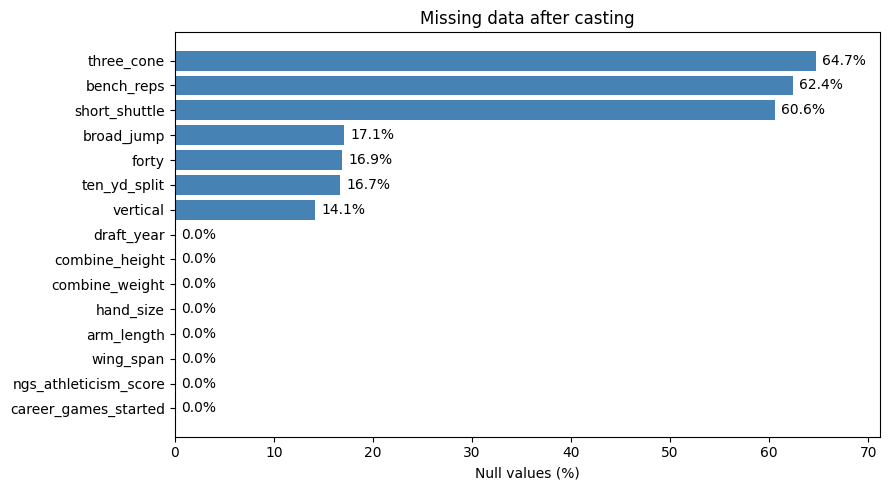

In [0]:
# ── Percentage of nulls per numeric feature column (after casting) ──
import matplotlib.pyplot as plt

# Work on the post-cast joined frame
ml_joined_df = dataframes["ml_joined_df"]

# Identify numeric feature columns automatically (exclude ids and the target tg_career_start)
feature_cols = [
    c for c, t in ml_joined_df.dtypes
    if t in ("double", "float", "int", "bigint", "smallint", "tinyint", "decimal(10,0)")
    and c not in ("nfl_id", "tg_career_start")
]

total_rows = ml_joined_df.count()

# Compute null percentage per feature
null_pct_rows = ml_joined_df.agg(
    *[
        (F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)) / F.lit(total_rows) * 100).alias(c)
        for c in feature_cols
    ]
).collect()[0]

null_pct = {c: float(null_pct_rows[c]) for c in feature_cols}

# Build a summary Spark DataFrame and display it as a table
null_summary_df = spark.createDataFrame(
    [(c, round(v, 2)) for c, v in null_pct.items()],
    ["feature", "null_percent"],
)
display(null_summary_df)

# ── Horizontal bar chart: most → least missing ──
sorted_pct = sorted(null_pct.items(), key=lambda kv: kv[1], reverse=True)
features = [k for k, _ in sorted_pct]
pcts = [v for _, v in sorted_pct]

plt.figure(figsize=(9, 5))
plt.barh(features, pcts, color="steelblue")
plt.gca().invert_yaxis()  # most-missing at the top
plt.xlabel("Null values (%)")
plt.title("Missing data after casting")
plt.xlim(0, max(pcts) * 1.1 if pcts else 1)
for i, v in enumerate(pcts):
    plt.text(v + max(pcts) * 0.01 if pcts else 0, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()


###2.2.2 Summary statistics

In [0]:
# ── Summary statistics for numeric feature columns and the target tg_career_start ──
from pyspark.sql import functions as F

ml_modeling_df = dataframes["ml_modeling_df"]

# Numeric feature columns (exclude identifiers and position string)
summary_cols = [
    c for c, t in ml_modeling_df.dtypes
    if t in ("double", "float", "int", "bigint", "smallint", "tinyint", "decimal(10,0)")
    and c not in ("nfl_id",)
]

summary_df = (ml_modeling_df
    .summary("count", "mean", "stddev", "min", "50%", "max")
    .select(
        "summary",
        *[F.round(c, 2).cast("double").alias(c) for c in summary_cols],
    )
)

display(summary_df)


summary,ten_yd_split,forty,vertical,broad_jump,tg_career_start
count,510.0,510.0,510.0,510.0,510.0
mean,1.64,4.74,33.76,118.11,7.85
stddev,0.11,0.3,3.98,8.65,11.47
min,1.46,4.28,23.0,93.0,0.0
50%,1.59,4.65,34.0,120.0,2.0
max,1.96,5.48,44.0,138.0,50.0


### 2.2.3 What does the Target look like?

Share of players with tg_career_start = 0: 40.8% (208 of 510 players)


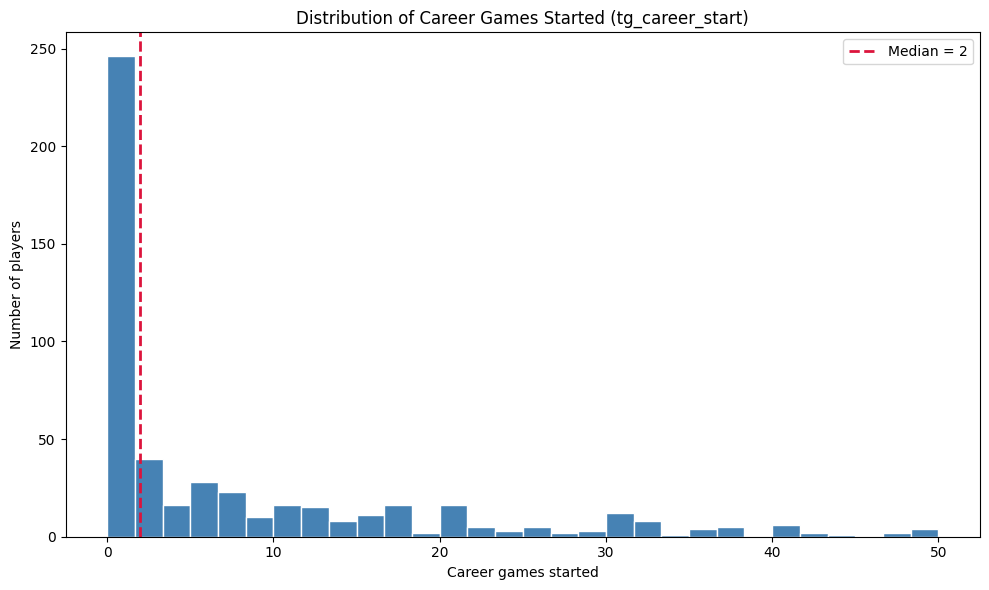

In [0]:
# ── Histogram of tg_career_start (career games started) with median line ──
import matplotlib.pyplot as plt

ml_modeling_df = dataframes["ml_modeling_df"]

# Pull just the target column into pandas for plotting
tg_career_start_pd = ml_modeling_df.select("tg_career_start").toPandas()["tg_career_start"]

# Share of players with career_games_started == 0
zero_share = float((tg_career_start_pd == 0).mean())
print(f"Share of players with tg_career_start = 0: {zero_share:.1%} ({(tg_career_start_pd == 0).sum()} of {len(tg_career_start_pd)} players)")

# Plot histogram with 30 bins
plt.figure(figsize=(10, 6))
plt.hist(tg_career_start_pd.dropna(), bins=30, color="steelblue", edgecolor="white")

# Vertical line at the median
median_val = tg_career_start_pd.median()
plt.axvline(median_val, color="crimson", linestyle="--", linewidth=2,
            label=f"Median = {median_val:.0f}")

plt.title("Distribution of Career Games Started (tg_career_start)")
plt.xlabel("Career games started")
plt.ylabel("Number of players")
plt.legend()
plt.tight_layout()
plt.show()


###2.2.4 Position Matters

+----------------+------------+-------------------+
|combine_position|player_count|avg_tg_career_start|
+----------------+------------+-------------------+
|DB              |122         |7.37               |
|OL              |121         |10.96              |
|DL              |118         |5.71               |
|WR              |107         |7.44               |
|TE              |42          |7.38               |
+----------------+------------+-------------------+



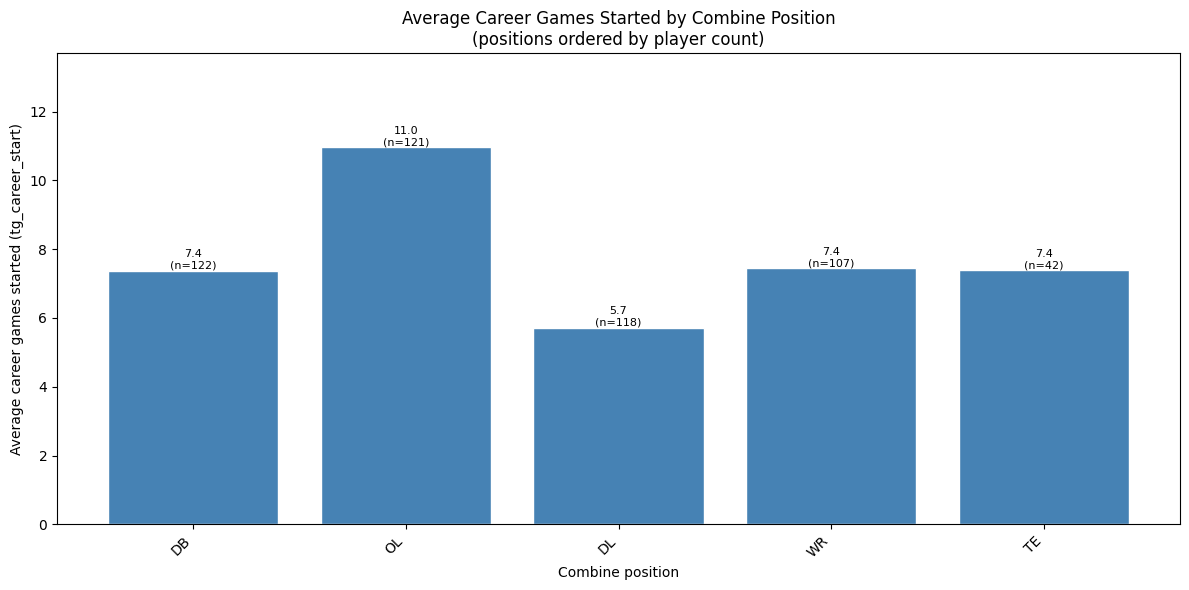

In [0]:
# ── Player count and average tg_career_start (career games started) by combine position ──
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

ml_modeling_df = dataframes["ml_modeling_df"]

# Aggregate: number of players and mean tg_career_start per combine position
pos_summary_df = (ml_modeling_df
    .groupBy("combine_position")
    .agg(
        F.count("nfl_id").alias("player_count"),
        F.round(F.avg("tg_career_start"), 2).alias("avg_tg_career_start"),
    )
    .orderBy(F.col("player_count").desc())
)

pos_summary_df.show(truncate=False)

# ── Bar chart: average tg_career_start by position (ordered by player count) ──
pos_pd = pos_summary_df.toPandas()

plt.figure(figsize=(12, 6))
plt.bar(pos_pd["combine_position"], pos_pd["avg_tg_career_start"], color="steelblue", edgecolor="white")

# Annotate each bar with its value and player count
for i, (avg_val, cnt) in enumerate(zip(pos_pd["avg_tg_career_start"], pos_pd["player_count"])):
    plt.text(i, avg_val, f"{avg_val:.1f}\n(n={cnt})", ha="center", va="bottom", fontsize=8)

plt.xlabel("Combine position")
plt.ylabel("Average career games started (tg_career_start)")
plt.title("Average Career Games Started by Combine Position\n(positions ordered by player count)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, pos_pd["avg_tg_career_start"].max() * 1.25 if len(pos_pd) else 1)
plt.tight_layout()
plt.show()


### 2.2.5 Correlation heatmap

Rows used (after dropping nulls): 510



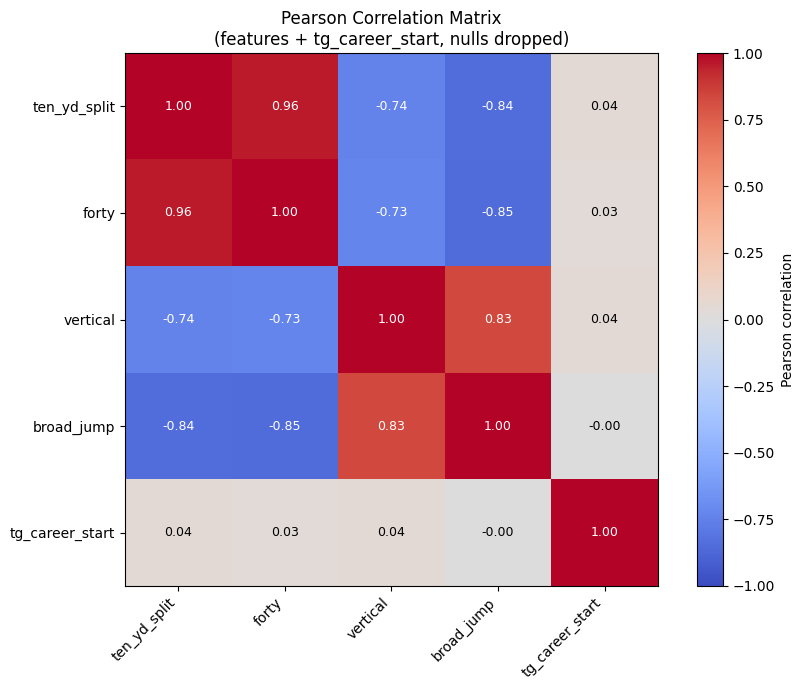

In [0]:
# ── Pearson correlation matrix (numeric features + tg_career_start) as a heatmap ──
import matplotlib.pyplot as plt
import numpy as np

ml_modeling_df = dataframes["ml_modeling_df"]

# Numeric columns to correlate (exclude identifiers)
corr_cols = [
    c for c, t in ml_modeling_df.dtypes
    if t in ("double", "float", "int", "bigint", "smallint", "tinyint")
    and c not in ("nfl_id",)
]

# Drop nulls, pull to pandas, compute Pearson correlation
corr_pd = ml_modeling_df.select(corr_cols).dropna().toPandas()
corr_matrix = corr_pd.corr(method="pearson")

print(f"Rows used (after dropping nulls): {len(corr_pd)}\n")

# ── Heatmap with imshow ──
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_matrix.values, cmap="coolwarm", vmin=-1, vmax=1)

# Column names on both axes
labels = corr_matrix.columns
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)

# Print the correlation value in each cell
corr_vals = corr_matrix.values
for i in range(corr_vals.shape[0]):
    for j in range(corr_vals.shape[1]):
        ax.text(j, i, f"{corr_vals[i, j]:.2f}",
                ha="center", va="center",
                color="white" if abs(corr_vals[i, j]) > 0.5 else "black",
                fontsize=9)

plt.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Pearson Correlation Matrix\n(features + tg_career_start, nulls dropped)")
plt.tight_layout()
plt.show()


## 2.3 MLflow experiments

| Setting | Value | Meaning |
|---|---|---|
| `regParam` | 0, 0.01, 0.1, 1.0 | How strong the penalty is. 0 = no penalty (plain OLS). |
| `elasticNetParam` | 0 | Ridge (L2): shrinks all coefficients towards zero. |
| `elasticNetParam` | 1 | Lasso (L1): can set some coefficients exactly to zero. |
| `elasticNetParam` | 0.5 | Elastic Net: half Ridge, half Lasso. |
| `solver` | `normal` | Solves the equations in one shot (closed form). |
| `solver` | `l-bfgs` | Improves the answer step by step (iterative). |
| `solver` | `auto` | Spark picks for you. |

### 2.3.1 Split the data and build the pipeline

In [0]:
# ── 2.3.1 Split 60/20/20 (seed 42) and build the Spark ML pipeline stages ──
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.evaluation import RegressionEvaluator

ml_modeling_df = dataframes["ml_modeling_df"]

# ── Step 1: Split into train / validation / test (60/20/20, seed 42) ──
train_df, val_df, test_df = ml_modeling_df.randomSplit([0.6, 0.2, 0.2], seed=42)

dataframes["train_df"] = train_df
dataframes["val_df"] = val_df
dataframes["test_df"] = test_df

print(f"train rows: {train_df.count():,}")
print(f"val   rows: {val_df.count():,}")
print(f"test  rows: {test_df.count():,}")

# ── Step 2: Identify numeric feature columns (exclude ids, position, target) ──
numeric_features = [
    c for c, t in ml_modeling_df.dtypes
    if t in ("double", "float", "int", "bigint", "smallint", "tinyint")
    and c not in ("nfl_id", "tg_career_start")
]
print(f"\nNumeric features to impute: {numeric_features}")

# ── Step 3: Build the pipeline stages ──
imputer = Imputer(
    inputCols=numeric_features,
    outputCols=[f"{c}_imp" for c in numeric_features],
    strategy="median",
)

position_indexer = StringIndexer(
    inputCol="combine_position",
    outputCol="combine_position_idx",
    handleInvalid="keep",
)

position_encoder = OneHotEncoder(
    inputCol="combine_position_idx",
    outputCol="combine_position_ohe",
)

assembler = VectorAssembler(
    inputCols=[f"{c}_imp" for c in numeric_features] + ["combine_position_ohe"],
    outputCol="features",
)

pipeline = Pipeline(stages=[imputer, position_indexer, position_encoder, assembler])
dataframes["ml_pipeline"] = pipeline

print(f"\nPipeline stages: {[s.__class__.__name__ for s in pipeline.getStages()]}")

# ── Step 4: Helper to evaluate a regression model on given data ──
def evaluate(model, data):
    """Return RMSE, MAE and R2 for a fitted model on the given DataFrame."""
    preds = model.transform(data)
    metrics = {}
    for name, metric in [("RMSE", "rmse"), ("MAE", "mae"), ("R2", "r2")]:
        evaluator = RegressionEvaluator(
            labelCol="tg_career_start", predictionCol="prediction", metricName=metric
        )
        metrics[name] = evaluator.evaluate(preds)
    return metrics

print("\n✅ evaluate(model, data) helper ready — returns {'RMSE', 'MAE', 'R2'} on tg_career_start.")


train rows: 322
val   rows: 95
test  rows: 93

Numeric features to impute: ['ten_yd_split', 'forty', 'vertical', 'broad_jump']

Pipeline stages: ['Imputer', 'StringIndexer', 'OneHotEncoder', 'VectorAssembler']

✅ evaluate(model, data) helper ready — returns {'RMSE', 'MAE', 'R2'} on tg_career_start.


###2.3.2 Run the experiment grid

In [0]:
# ── 2.3.2 Run the LinearRegression grid: OLS / Ridge / Lasso / ElasticNet × solver under one parent MLflow run ──
import time
import mlflow
from pyspark.ml import Pipeline
from pyspark.ml.regression import LinearRegression

train_df = dataframes["train_df"]
val_df = dataframes["val_df"]
base_stages = dataframes["ml_pipeline"].getStages()

ml_modeling_df = dataframes["ml_modeling_df"]

# Numeric feature columns in the same order used by the VectorAssembler in 2.3.1
numeric_features = [
    c for c, t in ml_modeling_df.dtypes
    if t in ("double", "float", "int", "bigint", "smallint", "tinyint")
    and c not in ("nfl_id", "tg_career_start")
]
print(f"Numeric features (coef_<feature> order): {numeric_features}\n")

# ── Step 1: Build the experiment grid ──
# (penalty name, regParam, elasticNetParam)
penalty_settings = [("OLS", 0.0, 0.0)] + [
    (name, lam, en)
    for name, en in [("Ridge", 0.0), ("Lasso", 1.0), ("ElasticNet", 0.5)]
    for lam in [0.01, 0.1, 1.0]
]
solvers = ["auto", "normal", "l-bfgs"]

total_fits = len(penalty_settings) * len(solvers)
print(f"Total fits: {total_fits} ({len(penalty_settings)} penalty settings × {len(solvers)} solvers)\n")

# ── Step 2: Fitted-model registry (run name + val_rmse) ──
fitted_models = []   # list of dicts: {run_name, val_rmse, penalty, regParam, elasticNetParam, solver, model}
failed_runs = []     # run names that raised during fit/eval

# ── Step 3: Parent MLflow run with one nested child run per combination ──
with mlflow.start_run(run_name="NFL_LinReg_grid") as parent_run:
    mlflow.set_tag("grid", "LinearRegression_penalty_solver")

    fit_no = 0
    for penalty, reg_param, en_param in penalty_settings:
        for solver in solvers:
            fit_no += 1
            run_name = f"{penalty}_lam{reg_param:g}_{solver}"

            with mlflow.start_run(run_name=run_name, nested=True) as child_run:
                try:
                    # ── Fit: preprocessing pipeline stages + LinearRegression ──
                    lr = LinearRegression(
                        featuresCol="features",
                        labelCol="tg_career_start",
                        regParam=reg_param,
                        elasticNetParam=en_param,
                        solver=solver,
                    )
                    full_pipeline = Pipeline(stages=base_stages + [lr])

                    t0 = time.time()
                    fitted = full_pipeline.fit(train_df)
                    fit_seconds = time.time() - t0

                    # ── Extract model internals ──
                    lr_model = fitted.stages[-1]
                    coefs = lr_model.coefficients.toArray()

                    # ── Evaluate on the validation set (RMSE / MAE / R2) ──
                    val_metrics = evaluate(fitted, val_df)

                    # ── Log params ──
                    mlflow.log_params({
                        "penalty": penalty,
                        "regParam": reg_param,
                        "elasticNetParam": en_param,
                        "solver": solver,
                    })

                    # ── Log metrics ──
                    mlflow.log_metrics({
                        "val_rmse": float(val_metrics["RMSE"]),
                        "val_mae": float(val_metrics["MAE"]),
                        "val_r2": float(val_metrics["R2"]),
                        "fit_seconds": fit_seconds,
                        "totalIterations": float(lr_model.summary.totalIterations),
                        "zero_coefficients": float(sum(1 for c in coefs if abs(c) < 1e-8)),
                    })

                    # One metric per numeric feature: first coefficients, same order as numeric columns
                    mlflow.log_metrics({
                        f"coef_{f}": float(coefs[i]) for i, f in enumerate(numeric_features)
                    })

                    mlflow.set_tag("status", "succeeded")

                    fitted_models.append({
                        "run_name": run_name,
                        "val_rmse": float(val_metrics["RMSE"]),
                        "penalty": penalty,
                        "regParam": reg_param,
                        "elasticNetParam": en_param,
                        "solver": solver,
                        "model": fitted,
                    })

                    print(f"[{fit_no:>2d}/{total_fits}] ✅ {run_name:<28s} "
                          f"val_rmse={val_metrics['RMSE']:.3f}  "
                          f"val_r2={val_metrics['R2']:.3f}  "
                          f"iters={lr_model.summary.totalIterations}  "
                          f"zero_coefs={int(sum(1 for c in coefs if abs(c) < 1e-8))}")

                except Exception as e:
                    # ── Failure path: tag the child run and record the error message ──
                    mlflow.set_tag("status", "failed")
                    mlflow.log_param("error", str(e))
                    failed_runs.append(run_name)
                    print(f"[{fit_no:>2d}/{total_fits}] ❌ {run_name:<28s} failed: {str(e).splitlines()[0]}")

# ── Step 4: Summary ──
print("\n" + "═" * 60)
print(f"Fits succeeded: {len(fitted_models)} / {total_fits}   failed: {len(failed_runs)}")
if failed_runs:
    print(f"Failed runs: {failed_runs}")

print("\nTop 5 by val_rmse:")
for m in sorted(fitted_models, key=lambda m: m["val_rmse"])[:5]:
    print(f"  {m['run_name']:<28s} val_rmse={m['val_rmse']:.3f}")

print(f"\n✅ fitted_models holds {len(fitted_models)} fitted pipelines with run names and val_rmse.")

Numeric features (coef_<feature> order): ['ten_yd_split', 'forty', 'vertical', 'broad_jump']

Total fits: 30 (10 penalty settings × 3 solvers)



2026/11/02 00:05:43 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.
2026/11/02 00:05:43 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.
2026/11/02 00:05:58 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


[ 1/30] ✅ OLS_lam0_auto                val_rmse=9.833  val_r2=-0.004  iters=25  zero_coefs=0


2026/11/02 00:06:07 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


[ 2/30] ✅ OLS_lam0_normal              val_rmse=9.833  val_r2=-0.004  iters=25  zero_coefs=0


...

[27/30] ✅ ElasticNet_lam0.1_l-bfgs     val_rmse=9.763  val_r2=0.010  iters=95  zero_coefs=2


2026/11/02 00:10:34 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


[28/30] ✅ ElasticNet_lam1_auto         val_rmse=9.544  val_r2=0.054  iters=21  zero_coefs=4


2026/11/02 00:10:42 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.


[29/30] ✅ ElasticNet_lam1_normal       val_rmse=9.544  val_r2=0.054  iters=21  zero_coefs=4
[30/30] ✅ ElasticNet_lam1_l-bfgs       val_rmse=9.544  val_r2=0.054  iters=21  zero_coefs=4

════════════════════════════════════════════════════════════
Fits succeeded: 30 / 30   failed: 0

Top 5 by val_rmse:
  ElasticNet_lam1_l-bfgs       val_rmse=9.544
  ElasticNet_lam1_auto         val_rmse=9.544
  ElasticNet_lam1_normal       val_rmse=9.544
  Lasso_lam1_auto              val_rmse=9.642
  Lasso_lam1_normal            val_rmse=9.642

✅ fitted_models holds 30 fitted pipelines with run names and val_rmse.


###2.3.3 Quick health check

In [0]:
# ── Count child runs under the NFL_LinReg_grid parent run: succeeded vs tagged failed ──
import mlflow

# Search across all experiments so the parent run is found regardless of experiment name
all_exps = [e.experiment_id for e in mlflow.search_experiments()]

# ── Step 1: Locate the parent run (most recent, in case the grid was re-run) ──
parent_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string="tags.mlflow.runName = 'NFL_LinReg_grid'",
    order_by=["attributes.start_time DESC"],
    max_results=1,
)

if parent_df.empty:
    raise ValueError("Parent run 'NFL_LinReg_grid' not found in any experiment.")

parent_run_id = parent_df.iloc[0]["run_id"]
print(f"Parent run NFL_LinReg_grid found: {parent_run_id}\n")

# ── Step 2: Fetch all child runs nested under the parent ──
children_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string=f"tags.mlflow.parentRunId = '{parent_run_id}'",
)

# ── Step 3: Count by the 'status' tag set during the grid run ──
succeeded = int((children_df["tags.status"] == "succeeded").sum())
failed = int((children_df["tags.status"] == "failed").sum())
other = len(children_df) - succeeded - failed

print("═" * 45)
print(f"Total child runs under NFL_LinReg_grid: {len(children_df)}")
print(f"  ✅ tagged 'succeeded': {succeeded}")
print(f"  ❌ tagged 'failed':    {failed}")
if other:
    print(f"  ⚠️ other / no status tag: {other}")
print("═" * 45)

# ── Step 4: List the failed run names (if any) ──
failed_names = children_df.loc[children_df["tags.status"] == "failed", "tags.mlflow.runName"].tolist()
if failed_names:
    print("\nFailed runs:")
    for name in failed_names:
        print(f"  - {name}")


Parent run NFL_LinReg_grid found: 7cd3e7c37f3b49daa39f9ec489402342

═════════════════════════════════════════════
Total child runs under NFL_LinReg_grid: 30
  ✅ tagged 'succeeded': 30
  ❌ tagged 'failed':    0
═════════════════════════════════════════════


##2.4 Visualizing the MLFlow Experiments

| Metric | Meaning | Better when |
|---|---|---|
| RMSE | Typical prediction error in games started; large misses count extra | Lower |
| MAE | Average prediction error in games started | Lower |
| R² | Share of variation in games started the model explains (0 to 1) | Higher |
| zero_coefficients | Features the model switched off | Higher = simpler model |
| fit_seconds, totalIterations | Cost of training | Lower |

###2.4.1 Leaderboard

In [0]:
# ── 2.4.1 Leaderboard: all child runs of NFL_LinReg_grid, sorted by val_rmse ──
import mlflow
import pandas as pd

# ── Step 1: Locate the parent run (most recent NFL_LinReg_grid) ──
all_exps = [e.experiment_id for e in mlflow.search_experiments()]

parent_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string="tags.mlflow.runName = 'NFL_LinReg_grid'",
    order_by=["attributes.start_time DESC"],
    max_results=1,
)

if parent_df.empty:
    raise ValueError("Parent run 'NFL_LinReg_grid' not found in any experiment.")

parent_run_id = parent_df.iloc[0]["run_id"]
print(f"Parent run NFL_LinReg_grid: {parent_run_id}\n")

# ── Step 2: Fetch all child runs under the parent ──
children_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string=f"tags.mlflow.parentRunId = '{parent_run_id}'",
)

# ── Step 3: Build the leaderboard DataFrame ──
cols = {
    "tags.mlflow.runName": "run_name",
    "params.penalty": "penalty",
    "params.regParam": "regParam",
    "params.solver": "solver",
    "metrics.val_rmse": "val_rmse",
    "metrics.val_mae": "val_mae",
    "metrics.val_r2": "val_r2",
    "metrics.zero_coefficients": "zero_coefficients",
    "metrics.totalIterations": "totalIterations",
    "metrics.fit_seconds": "fit_seconds",
}

runs = (
    children_df[list(cols.keys())]
    .rename(columns=cols)
    .sort_values("val_rmse", ascending=True)
    .reset_index(drop=True)
)

# Tidy numeric columns
num_cols = ["val_rmse", "val_mae", "val_r2", "zero_coefficients", "totalIterations", "fit_seconds"]
for c in num_cols:
    runs[c] = pd.to_numeric(runs[c], errors="coerce")
runs["regParam"] = pd.to_numeric(runs["regParam"], errors="coerce")

# ── Step 4: Display with the best (lowest val_rmse) row highlighted ──
best_idx = runs["val_rmse"].idxmin()

styled = (
    runs.style
    .apply(lambda row: ["background-color: #d4ffd4; font-weight: bold" if row.name == best_idx else "" for _ in row], axis=1)
    .format({
        "val_rmse": "{:.3f}",
        "val_mae": "{:.3f}",
        "val_r2": "{:.3f}",
        "fit_seconds": "{:.1f}",
    })
    .hide(axis="index")
    .set_caption(f"MLflow leaderboard: {len(runs)} child runs of NFL_LinReg_grid (sorted by val_rmse ↑, best row highlighted)")
)

displayHTML(styled.to_html())

print(f"\nBest run: {runs.loc[best_idx, 'run_name']} (val_rmse={runs.loc[best_idx, 'val_rmse']:.3f})")


Parent run NFL_LinReg_grid: 7cd3e7c37f3b49daa39f9ec489402342



run_name,penalty,regParam,solver,val_rmse,val_mae,val_r2,zero_coefficients,totalIterations,fit_seconds
ElasticNet_lam1_l-bfgs,ElasticNet,1.000000,l-bfgs,9.544,7.579,0.054,4.000000,21.000000,5.4
ElasticNet_lam1_normal,ElasticNet,1.000000,normal,9.544,7.578,0.054,4.000000,21.000000,4.8
ElasticNet_lam1_auto,ElasticNet,1.000000,auto,9.544,7.578,0.054,4.000000,21.000000,4.2
Lasso_lam1_auto,Lasso,1.000000,auto,9.642,7.728,0.035,7.000000,25.000000,4.5
Lasso_lam1_normal,Lasso,1.000000,normal,9.642,7.728,0.035,7.000000,25.000000,4.5
Lasso_lam1_l-bfgs,Lasso,1.000000,l-bfgs,9.642,7.729,0.035,7.000000,25.000000,6.6
Ridge_lam1_l-bfgs,Ridge,1.000000,l-bfgs,9.710,7.590,0.021,0.000000,19.000000,5.9
Ridge_lam1_auto,Ridge,1.000000,auto,9.710,7.590,0.021,0.000000,0.000000,5.2
Ridge_lam1_normal,Ridge,1.000000,normal,9.710,7.590,0.021,0.000000,0.000000,4.6
Lasso_lam0.1_normal,Lasso,0.100000,normal,9.724,7.576,0.019,2.000000,53.000000,5.0



Best run: ElasticNet_lam1_l-bfgs (val_rmse=9.544)


###2.4.2 Which penalty and strength work best?

Parent run NFL_LinReg_grid: 7cd3e7c37f3b49daa39f9ec489402342

Child runs with solver=auto: 10



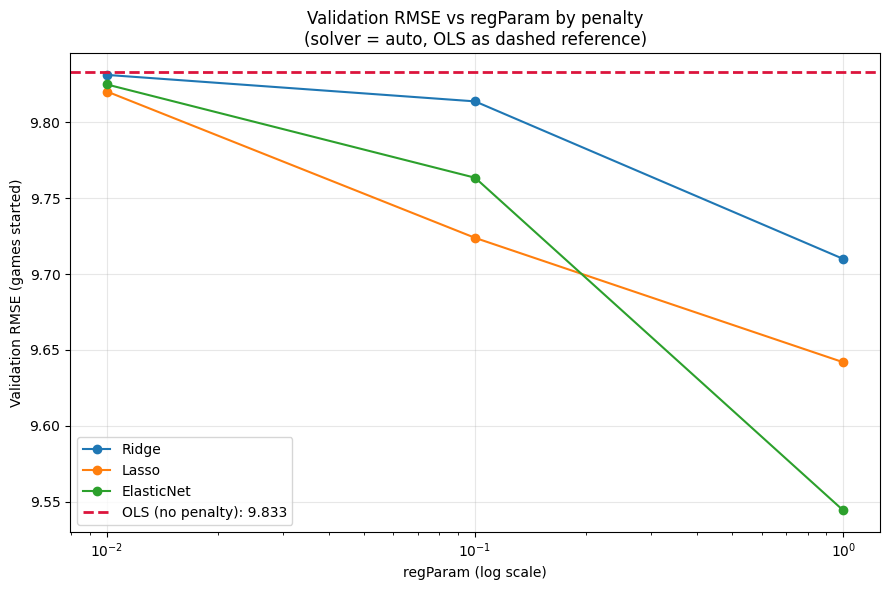

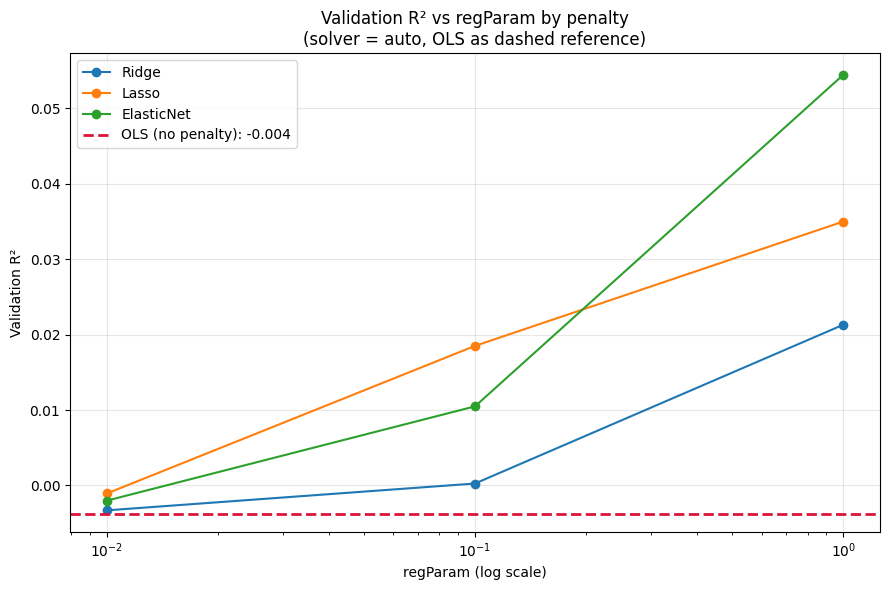

✅ Logged 'val_rmse_by_regparam_solver_auto.png' and 'val_r2_by_regparam_solver_auto.png' to the parent run.


In [0]:
# ── 2.4.2 Validation RMSE / R2 vs regParam (solver = auto), one line per penalty, OLS as reference ──
import mlflow
import matplotlib.pyplot as plt
import pandas as pd

# ── Step 1: Locate the parent run (most recent NFL_LinReg_grid) ──
all_exps = [e.experiment_id for e in mlflow.search_experiments()]

parent_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string="tags.mlflow.runName = 'NFL_LinReg_grid'",
    order_by=["attributes.start_time DESC"],
    max_results=1,
)

if parent_df.empty:
    raise ValueError("Parent run 'NFL_LinReg_grid' not found in any experiment.")

parent_run_id = parent_df.iloc[0]["run_id"]
print(f"Parent run NFL_LinReg_grid: {parent_run_id}\n")

# ── Step 2: Fetch all child runs under the parent ──
children_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string=f"tags.mlflow.parentRunId = '{parent_run_id}'",
)

# ── Step 3: Keep only solver = auto (and succeeded runs) ──
auto_df = children_df.loc[
    (children_df["params.solver"] == "auto") & (children_df["tags.status"] == "succeeded")
].copy()

# search_runs exposes params/metrics with 'params.'/'metrics.' prefixes — map to bare names
auto_df = auto_df.rename(columns={
    "params.regParam": "regParam",
    "metrics.val_rmse": "val_rmse",
    "metrics.val_r2": "val_r2",
})

for c in ["regParam", "val_rmse", "val_r2"]:
    auto_df[c] = pd.to_numeric(auto_df[c], errors="coerce")

print(f"Child runs with solver=auto: {len(auto_df)}\n")

# ── Step 4: OLS reference values (single run at regParam = 0) ──
ols_row = auto_df.loc[auto_df["params.penalty"] == "OLS"]
if ols_row.empty:
    raise ValueError("No OLS run with solver=auto found — cannot draw the reference line.")
ols_rmse = float(ols_row["val_rmse"].iloc[0])
ols_r2 = float(ols_row["val_r2"].iloc[0])

# ── Step 5: Build the two figures ──
penalty_colors = {"Ridge": "tab:blue", "Lasso": "tab:orange", "ElasticNet": "tab:green"}

fig_rmse, ax = plt.subplots(figsize=(9, 6))
fig_r2, ax2 = plt.subplots(figsize=(9, 6))

for penalty, color in penalty_colors.items():
    sub = (auto_df.loc[auto_df["params.penalty"] == penalty]
           .sort_values("regParam"))
    if sub.empty:
        print(f"⚠️ No runs found for penalty '{penalty}' with solver=auto")
        continue

    ax.plot(sub["regParam"], sub["val_rmse"], marker="o", color=color, label=penalty)
    ax2.plot(sub["regParam"], sub["val_r2"], marker="o", color=color, label=penalty)

# OLS horizontal reference line
ax.axhline(ols_rmse, color="crimson", linestyle="--", linewidth=2,
           label=f"OLS (no penalty): {ols_rmse:.3f}")
ax2.axhline(ols_r2, color="crimson", linestyle="--", linewidth=2,
            label=f"OLS (no penalty): {ols_r2:.3f}")

# ── Figure 1: val_rmse vs regParam ──
ax.set_xscale("log")
ax.set_xlabel("regParam (log scale)")
ax.set_ylabel("Validation RMSE (games started)")
ax.set_title("Validation RMSE vs regParam by penalty\n(solver = auto, OLS as dashed reference)")
ax.legend()
ax.grid(alpha=0.3)
fig_rmse.tight_layout()

# ── Figure 2: val_r2 vs regParam ──
ax2.set_xscale("log")
ax2.set_xlabel("regParam (log scale)")
ax2.set_ylabel("Validation R²")
ax2.set_title("Validation R² vs regParam by penalty\n(solver = auto, OLS as dashed reference)")
ax2.legend()
ax2.grid(alpha=0.3)
fig_r2.tight_layout()

plt.show()

# ── Step 6: Log both figures to the parent run ──
with mlflow.start_run(run_id=parent_run_id):
    mlflow.log_figure(fig_rmse, "val_rmse_by_regparam_solver_auto.png")
    mlflow.log_figure(fig_r2, "val_r2_by_regparam_solver_auto.png")

print("✅ Logged 'val_rmse_by_regparam_solver_auto.png' and 'val_r2_by_regparam_solver_auto.png' to the parent run.")


###2.4.3 What did Lasso switch off? (coefficient paths)

Parent run NFL_LinReg_grid: 7cd3e7c37f3b49daa39f9ec489402342

Features with logged coefficients: ['broad_jump', 'forty', 'ten_yd_split', 'vertical']



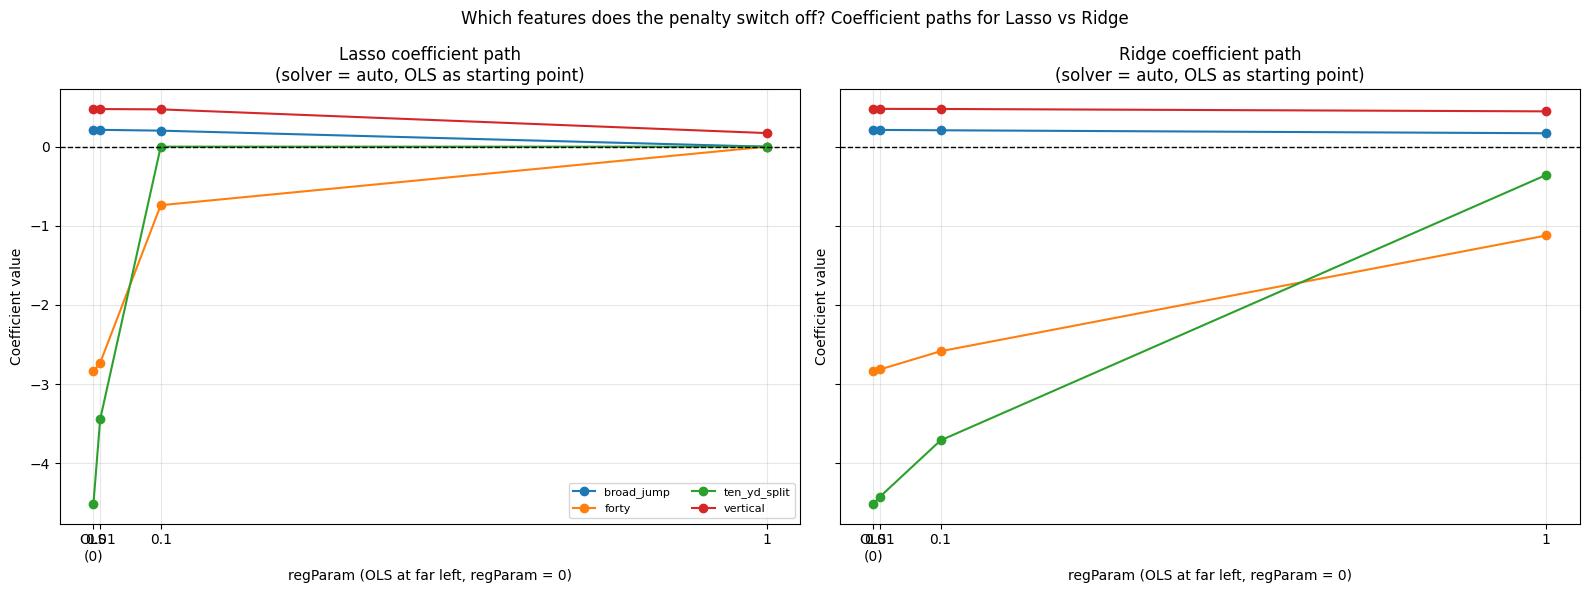

✅ Logged 'coef_paths_lasso_vs_ridge_solver_auto.png' to the parent run.


In [0]:
# ── 2.4.3 Coefficient paths: Lasso vs Ridge (solver = auto), one line per feature, OLS as starting point ──
import mlflow
import matplotlib.pyplot as plt
import pandas as pd

# ── Step 1: Locate the parent run (most recent NFL_LinReg_grid) ──
all_exps = [e.experiment_id for e in mlflow.search_experiments()]

parent_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string="tags.mlflow.runName = 'NFL_LinReg_grid'",
    order_by=["attributes.start_time DESC"],
    max_results=1,
)

if parent_df.empty:
    raise ValueError("Parent run 'NFL_LinReg_grid' not found in any experiment.")

parent_run_id = parent_df.iloc[0]["run_id"]
print(f"Parent run NFL_LinReg_grid: {parent_run_id}\n")

# ── Step 2: Fetch all child runs under the parent ──
children_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string=f"tags.mlflow.parentRunId = '{parent_run_id}'",
)

# ── Step 3: Keep solver = auto, succeeded runs, penalties Lasso / Ridge / OLS ──
auto_df = children_df.loc[
    (children_df["params.solver"] == "auto")
    & (children_df["tags.status"] == "succeeded")
    & (children_df["params.penalty"].isin(["Lasso", "Ridge", "OLS"]))
].copy()

auto_df["regParam"] = pd.to_numeric(auto_df["params.regParam"], errors="coerce")

# ── Step 4: Identify the coef_ metric columns (one per feature) ──
coef_cols = sorted(c for c in auto_df.columns if c.startswith("metrics.coef_"))
features = [c[len("metrics.coef_"):] for c in coef_cols]
if not coef_cols:
    raise ValueError("No metrics.coef_* columns found in the child runs.")

for c in coef_cols:
    auto_df[c] = pd.to_numeric(auto_df[c], errors="coerce")

print(f"Features with logged coefficients: {features}\n")

# ── Step 5: Helper to pull the run row for a penalty / regParam combo ──
def get_row(penalty, reg_param):
    sub = auto_df.loc[(auto_df["params.penalty"] == penalty) & (auto_df["regParam"] == reg_param)]
    if sub.empty:
        raise ValueError(f"No succeeded run found for {penalty} at regParam={reg_param} with solver=auto.")
    return sub.iloc[0]

ols_row = get_row("OLS", 0.0)

# regParam values shared by Lasso and Ridge (OLS sits at regParam = 0, far left)
reg_params = sorted(auto_df.loc[auto_df["params.penalty"].isin(["Lasso", "Ridge"]), "regParam"].unique())
xs = [0.0] + list(reg_params)
x_labels = ["OLS\n(0)"] + [f"{rp:g}" for rp in reg_params]

# ── Step 6: Side-by-side coefficient paths: Lasso vs Ridge ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, penalty in zip(axes, ["Lasso", "Ridge"]):
    for col, feature in zip(coef_cols, features):
        ys = [ols_row[col]] + [get_row(penalty, rp)[col] for rp in reg_params]
        ax.plot(xs, ys, marker="o", label=feature)

    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_xticks(xs)
    ax.set_xticklabels(x_labels)
    ax.set_xlabel("regParam (OLS at far left, regParam = 0)")
    ax.set_ylabel("Coefficient value")
    ax.set_title(f"{penalty} coefficient path\n(solver = auto, OLS as starting point)")
    ax.grid(alpha=0.3)

axes[0].legend(fontsize=8, ncol=2)
fig.suptitle("Which features does the penalty switch off? Coefficient paths for Lasso vs Ridge")
fig.tight_layout()
plt.show()

# ── Step 7: Log the figure to the parent run ──
with mlflow.start_run(run_id=parent_run_id):
    mlflow.log_figure(fig, "coef_paths_lasso_vs_ridge_solver_auto.png")

print("✅ Logged 'coef_paths_lasso_vs_ridge_solver_auto.png' to the parent run.")


### 2.4.4 Do solvers change the answer or only the cost?


Logged figures to parent run: 7cd3e7c37f3b49daa39f9ec489402342


params.solver,val_rmse,fit_seconds,total_iterations,n_runs
auto,9.813814545122403,4.745356559753418,0.0,1
l-bfgs,9.813786358067393,6.427823781967163,25.0,1
normal,9.813814545122403,4.672301292419434,0.0,1


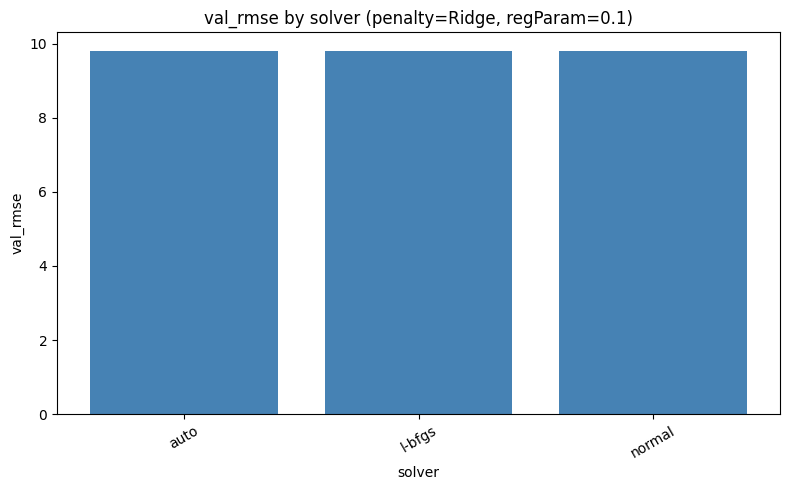

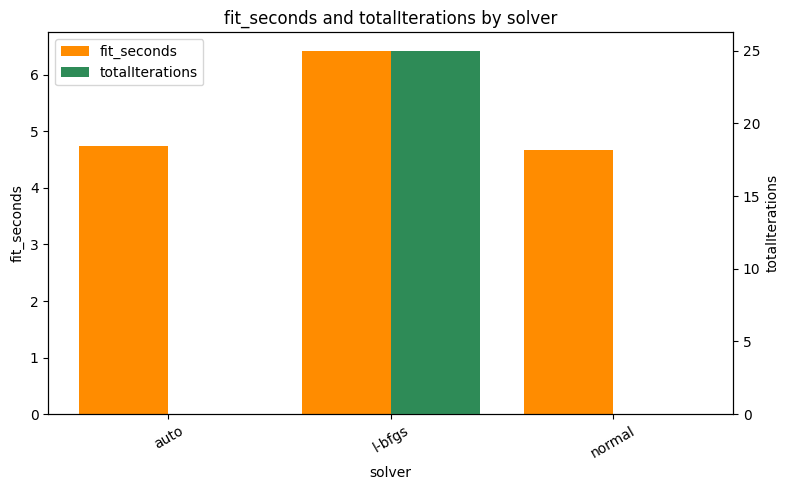

In [0]:
import mlflow
from mlflow.tracking import MlflowClient
import matplotlib.pyplot as plt

client = MlflowClient()

# --- Collect runs matching penalty=Ridge, regParam=0.1 ---
runs = mlflow.search_runs(
    filter_string="params.penalty = 'Ridge' and params.regParam = '0.1'",
    order_by=["params.solver ASC"],
)
assert not runs.empty, "No runs found with penalty=Ridge and regParam=0.1"

# --- Resolve the parent run to log figures into ---
active = mlflow.active_run() or mlflow.last_active_run()
parent_run_id = (active.data.tags.get("mlflow.parentRunId") if active else None) or active.info.run_id

# One row per solver (mean across matching runs, with run counts)
grouped = (
    runs.groupby("params.solver", sort=True)
    .agg(
        val_rmse=("metrics.val_rmse", "mean"),
        fit_seconds=("metrics.fit_seconds", "mean"),
        total_iterations=("metrics.totalIterations", "mean"),
        n_runs=("run_id", "count"),
    )
    .reset_index()
)
solvers = grouped["params.solver"].tolist()
x = range(len(solvers))

# --- Chart 1: val_rmse per solver ---
fig1, ax1 = plt.subplots(figsize=(8, 5))
ax1.bar(x, grouped["val_rmse"], color="steelblue")
ax1.set_xticks(list(x))
ax1.set_xticklabels(solvers, rotation=30)
ax1.set_xlabel("solver")
ax1.set_ylabel("val_rmse")
ax1.set_title("val_rmse by solver (penalty=Ridge, regParam=0.1)")
fig1.tight_layout()

# --- Chart 2: fit_seconds and totalIterations per solver (grouped, twin axes) ---
width = 0.4
fig2, ax2 = plt.subplots(figsize=(8, 5))
ax3 = ax3 = ax2.twinx()
ax2.bar([i - width / 2 for i in x], grouped["fit_seconds"], width=width, label="fit_seconds", color="darkorange")
ax3.bar([i + width / 2 for i in x], grouped["total_iterations"], width=width, label="totalIterations", color="seagreen")
ax2.set_xticks(list(x))
ax2.set_xticklabels(solvers, rotation=30)
ax2.set_xlabel("solver")
ax2.set_ylabel("fit_seconds")
ax3.set_ylabel("totalIterations")
ax2.set_title("fit_seconds and totalIterations by solver")
h1, l1 = ax2.get_legend_handles_labels()
h2, l2 = ax3.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper left")
fig2.tight_layout()

# --- Log both figures to the parent run ---
client.log_figure(parent_run_id, fig1, "val_rmse_by_solver.png")
client.log_figure(parent_run_id, fig2, "fit_time_and_iterations_by_solver.png")

print(f"Logged figures to parent run: {parent_run_id}")
display(grouped)
plt.show()

###2.4.5 Final test score, error chart and registration

Best run by val_rmse: ElasticNet_lam1_l-bfgs  (val_rmse=9.5443)
Winning params: {'penalty': 'ElasticNet', 'regParam': 1.0, 'elasticNetParam': 0.5, 'solver': 'l-bfgs'}
Using the fitted pipeline from the grid run held in memory.

Test set (n=93): RMSE=12.8722  MAE=9.8457  R2=-0.0597


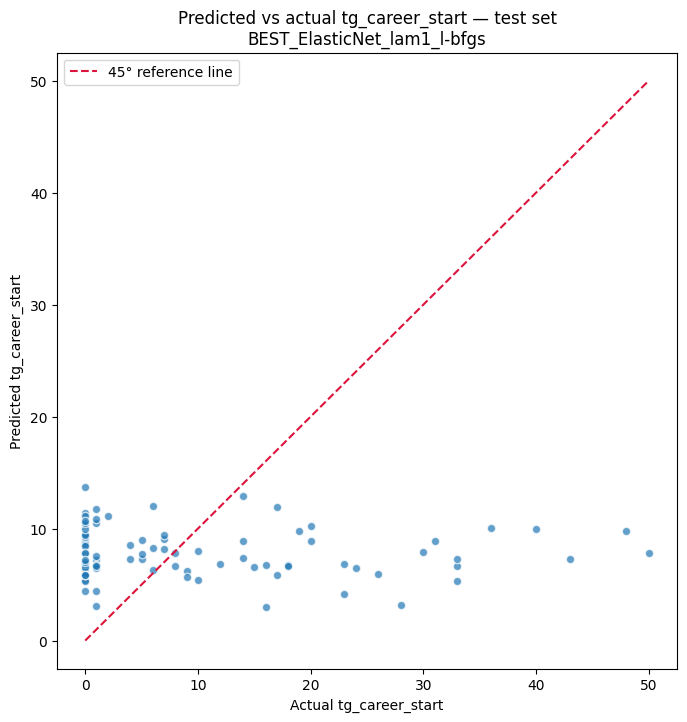

2026/11/02 00:43:18 WARNING mlflow.tracking.context.registry: Encountered unexpected error during resolving tags: getContext().extraContext() is not a CommandContext accessor, it is not available or is misspelled.



Inferred signature:
inputs: 
  ['ten_yd_split': double (required), 'forty': double (required), 'vertical': double (required), 'broad_jump': double (required), 'combine_position': string (required)]
outputs: 
  ['prediction': double (required)]
params: 
  None



2026/11/02 00:43:38 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /local_disk0/user_tmp_data/spark-9dfab02b-abd0-411a-897c-62/tmp_biowqkq/model, flavor: spark). Fall back to return ['pyspark==4.3.0']. Set logging level to DEBUG to see the full traceback. 
Registered model 'nfl_bigdatabowl.nfl_2027.nfl_games_started_lr' already exists. Creating a new version of this model...


Uploading artifacts:   0%|          | 0/50 [00:00<?, ?it/s]

🔗 Created version '2' of model 'nfl_bigdatabowl.nfl_2027.nfl_games_started_lr': https://dbc-1e30501c-741f.cloud.databricks.com/explore/data/models/nfl_bigdatabowl/nfl_2027/nfl_games_started_lr/version/2?o=7474651698890531



✅ BEST run logged: BEST_ElasticNet_lam1_l-bfgs (run id a412875355594236b47266ed2f64dc6c)
   Model logged to: runs:/a412875355594236b47266ed2f64dc6c/model
   Registered as:   nfl_bigdatabowl.nfl_2027.nfl_games_started_lr
   Registered version: nfl_bigdatabowl.nfl_2027.nfl_games_started_lr v2 (status: READY)


In [0]:
# ── 2.4.5 Final test score, predicted-vs-actual chart and model registration ──
# Pick the grid's fitted model with the lowest val_rmse, evaluate it ONCE on the held-out
# test set, log test_rmse / test_mae / test_r2 plus a predicted-vs-actual scatter plot to a
# new MLflow run named BEST_<run name>, then log the fitted Spark pipeline (signature inferred
# from 5 rows of raw features + the prediction column) and register it in Unity Catalog.

import os
import mlflow
import matplotlib.pyplot as plt
from mlflow.models import infer_signature
from pyspark.ml import Pipeline
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

DFS_TMPDIR = "/Volumes/nfl_bigdatabowl/nfl_2027/ml_tmp"
REGISTERED_MODEL_NAME = "nfl_bigdatabowl.nfl_2027.nfl_games_started_lr"

# Point SparkML / MLflow temp serialization at the UC volume (serverless-safe)
os.environ["SPARKML_TEMP_DFS_PATH"] = DFS_TMPDIR
os.environ["SPARK_ML_TMP_DFS_PATH"] = DFS_TMPDIR
os.environ["MLFLOW_DFS_TMP"] = DFS_TMPDIR

# ── Step 1: Locate the grid parent run and its child runs ──
all_exps = [e.experiment_id for e in mlflow.search_experiments()]
parent_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string="tags.mlflow.runName = 'NFL_LinReg_grid'",
    order_by=["attributes.start_time DESC"],
    max_results=1,
)
if parent_df.empty:
    raise ValueError("Parent run 'NFL_LinReg_grid' not found in any experiment.")
parent_run_id = parent_df.iloc[0]["run_id"]

children_df = mlflow.search_runs(
    experiment_ids=all_exps,
    filter_string=f"tags.mlflow.parentRunId = '{parent_run_id}'",
)

# ── Step 2: Best run = lowest val_rmse among succeeded children ──
best = (children_df
    .loc[children_df["tags.status"] == "succeeded"]
    .sort_values("metrics.val_rmse")
    .iloc[0])
best_run_name = best["tags.mlflow.runName"]
best_params = {
    "penalty": best["params.penalty"],
    "regParam": float(best["params.regParam"]),
    "elasticNetParam": float(best["params.elasticNetParam"]),
    "solver": best["params.solver"],
}
best_val_rmse = float(best["metrics.val_rmse"])
print(f"Best run by val_rmse: {best_run_name}  (val_rmse={best_val_rmse:.4f})")
print(f"Winning params: {best_params}")

# ── Step 3: Get the fitted pipeline (from grid memory if available, else refit same config) ──
for required in ("train_df", "val_df", "test_df", "ml_pipeline"):
    if required not in dataframes:
        raise ValueError(f"'{required}' missing from `dataframes` — re-run cell 2.3.1 (split & pipeline) first.")

test_df = dataframes["test_df"]
fitted = next(
    (e["model"] for e in globals().get("fitted_models", []) if e["run_name"] == best_run_name),
    None,
)
if fitted is None:
    lr = LinearRegression(
        featuresCol="features", labelCol="tg_career_start",
        regParam=best_params["regParam"],
        elasticNetParam=best_params["elasticNetParam"],
        solver=best_params["solver"],
    )
    fitted = Pipeline(stages=dataframes["ml_pipeline"].getStages() + [lr]).fit(dataframes["train_df"])
    print("Refit the winning configuration on the training split (grid fit no longer in memory).")
else:
    print("Using the fitted pipeline from the grid run held in memory.")

# ── Step 4: Predict ONCE on the held-out test set ──
RAW_FEATURE_COLS = ["ten_yd_split", "forty", "vertical", "broad_jump", "combine_position"]
preds = fitted.transform(test_df).select(*RAW_FEATURE_COLS, "tg_career_start", "prediction")
preds_pd = preds.toPandas()

# Same evaluators as the evaluate() helper in 2.3.1 (computed from the single test transform)
test_metrics = {
    name: RegressionEvaluator(
        labelCol="tg_career_start", predictionCol="prediction", metricName=name
    ).evaluate(preds)
    for name in ("rmse", "mae", "r2")
}
print(f"\nTest set (n={len(preds_pd)}): RMSE={test_metrics['rmse']:.4f}  "
      f"MAE={test_metrics['mae']:.4f}  R2={test_metrics['r2']:.4f}")

# ── Step 5: Scatter plot — predicted vs actual tg_career_start with a 45° reference line ──
lim = float(max(preds_pd["tg_career_start"].max(), preds_pd["prediction"].max()))
plt.figure(figsize=(8, 8))
plt.scatter(preds_pd["tg_career_start"], preds_pd["prediction"], alpha=0.7, edgecolor="white")
plt.plot([0, lim], [0, lim], "--", color="crimson", label="45° reference line")
plt.xlabel("Actual tg_career_start")
plt.ylabel("Predicted tg_career_start")
plt.title(f"Predicted vs actual tg_career_start — test set\nBEST_{best_run_name}")
plt.legend()
plot_path = "test_predicted_vs_actual.png"
plt.savefig(plot_path, dpi=120, bbox_inches="tight")
plt.show()

# ── Step 6: Infer the signature from 5 rows of raw feature columns + the prediction column ──
signature_rows = preds_pd.head(5)
signature = infer_signature(
    signature_rows[RAW_FEATURE_COLS],   # model input: raw (pre-pipeline) feature columns
    signature_rows[["prediction"]],     # model output
)
print(f"\nInferred signature:\n{signature}")

# ── Step 7: New MLflow run BEST_<run name> — test metrics, chart, and the model itself ──
with mlflow.start_run(run_name=f"BEST_{best_run_name}") as best_run:
    mlflow.log_params({**best_params, "best_grid_run": best_run_name})
    mlflow.log_metric("val_rmse", best_val_rmse)          # traceability: why this run won
    mlflow.log_metrics({
        "test_rmse": test_metrics["rmse"],
        "test_mae": test_metrics["mae"],
        "test_r2": test_metrics["r2"],
    })
    mlflow.set_tag("status", "succeeded")

    # Predicted-vs-actual scatter plot as a run artifact
    mlflow.log_artifact(plot_path)

    # The fitted Spark pipeline model (SparkML flavor) with signature + input example
    model_info = mlflow.spark.log_model(
        fitted,
        "model",
        signature=signature,
        input_example=signature_rows[RAW_FEATURE_COLS],
        dfs_tmpdir=DFS_TMPDIR,
        registered_model_name=REGISTERED_MODEL_NAME,
    )

    print(f"\n✅ BEST run logged: {best_run.info.run_name} (run id {best_run.info.run_id})")
    print(f"   Model logged to: {model_info.model_uri}")
    print(f"   Registered as:   {REGISTERED_MODEL_NAME}")

# ── Step 8: Confirm the registered model version in Unity Catalog ──
from mlflow.tracking import MlflowClient
versions = MlflowClient().search_model_versions(f"name = '{REGISTERED_MODEL_NAME}'")
for v in sorted(versions, key=lambda v: v.creation_timestamp, reverse=True)[:1]:
    print(f"   Registered version: {v.name} v{v.version} (status: {v.status})")
